# Стадия 1. Анализ данных о пациентах с циррозом печени

**Датасет:** [Playground Series S3E26](https://www.kaggle.com/competitions/playground-series-s3e26) (Kaggle).

**О чём данные.** 7 905 пациентов с первичным билиарным циррозом — хроническим заболеванием печени. По каждому пациенту записаны возраст, пол, принимаемый препарат, результаты анализов крови, признаки болезни (асцит, увеличение печени, сосудистые «паучки», отёки), стадия поражения печени и **итог наблюдения**: пациент жив, жив благодаря пересадке печени или умер.

**Конечная цель работы** — научиться по результатам обследования предсказывать итог наблюдения. Эта стадия готовит к тому фундамент.

---

## Задачи этой стадии

1. **Проверить, что данным можно доверять.** Нет ли пропусков, противоречий, физически невозможных значений (например, отрицательного числа тромбоцитов).

2. **Понять, как устроены данные.** Как распределены показатели, какие из них связаны с исходом, как связаны между собой.

3. **Привести данные в порядок.** Удалить записи, противоречащие протоколу исследования, и сделать показатели удобными для сравнения.

4. **Отобрать признаки для модели.** Это главная практическая задача стадии. Из 30 имеющихся столбцов нужно оставить такой набор, в котором:
   - нет столбцов, повторяющих друг друга (иначе одна и та же информация будет учтена дважды);
   - нет столбцов, не связанных с исходом;
   - нет столбцов, которые «подглядывают» в ответ — содержат информацию, известную только после наступления исхода.

5. **Разобраться с периодом наблюдения** — сколько дней пациент состоял под наблюдением. Этот столбец выглядит очень полезным, но его природа требует отдельного решения (блок 3.10).

## Что получается на выходе

| Файл | Содержимое | Для чего |
|---|---|---|
| `data/processed/train_clean.parquet` | все 30 столбцов после очистки | графики и проверки этой стадии |
| `data/processed/train_model.parquet` | 15 отобранных признаков и цель | вход моделей стадий 2 и 3 |

Дальше идут две стадии: **стадия 2** проверяет, применим ли к задаче самый простой линейный метод (оценка по числу), и **стадия 3** строит корректную модель предсказания исхода.

# **Часть 1. Загрузка данных**

## **1.1 Импорты и настройки**

In [1]:
# Стандартная библиотека Python
from math import pi
import os

# Сторонние библиотеки для анализа данных и визуализации
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats


## **1.2 Скачивание датасета из Kaggle**

In [2]:
# 1. Авторизация в Kaggle
kagglehub.login()

# 2. Корень проекта: папка с data/, найденная вверх по дереву от текущей директории.
#    Ноутбук лежит в project_notebooks/, данные — в data/ на уровень выше,
#    поэтому os.getcwd() напрямую использовать нельзя.
def find_project_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(d, 'data')):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            raise FileNotFoundError('Папка data/ не найдена вверх по дереву от ' + d)
        d = parent

PROJECT_ROOT = find_project_root()
local_dir = os.path.join(PROJECT_ROOT, 'data')
print('Корень проекта:', PROJECT_ROOT)

# 3. Скачивание файлов (раскомментировать для первичной загрузки)
# path = kagglehub.competition_download(
#     "playground-series-s3e26",
#     output_dir=local_dir,
#     force_download=True
# )
# print("Файлы успешно скачаны в:", path)
# print("Список файлов:", os.listdir(path))

Корень проекта: /media/gregory/Custom disk/repository/project1/ml-project-practice-1


In [3]:
# Загрузка обучающей выборки
df = pd.read_csv(f"{local_dir}/train.csv", index_col=0)


## **1.3 Описание данных**

Датасет: **Multi-Class Prediction of Cirrhosis Outcomes** (Playground Series S3E26).
Целевая переменная: `Status`.
Задача: многоклассовая классификация (предсказание вероятностей трёх классов).

**Фактические параметры выборки `train.csv`:** 7 905 строк × 19 столбцов (+ `id` как индекс), пропусков нет; типы при загрузке: int64(2) — `N_Days`, `Age`, float64(10) — лабораторные показатели, `Platelets`, `Stage`, object(7) — категориальные и целевая.

| Столбец | Тип | Описание |
|---------|-----|----------|
| `id` | int | Уникальный идентификатор записи (пациента). Не является признаком, используется только для сопоставления с `sample_submission.csv`. |
| `N_Days` | int | Количество дней наблюдения за пациентом с момента регистрации до последнего визита или события (смерти/трансплантации). |
| `Drug` | categorical | Принимаемый препарат: `D-penicillamine` (D-пеницилламин) или `Placebo` (плацебо). |
| `Age` | int | Возраст пациента в **днях** (не в годах!). Для перевода в годы: `Age / 365.25`. |
| `Sex` | categorical | Пол пациента: `M` (мужской) или `F` (женский). |
| `Ascites` | categorical | Наличие асцита (скопления жидкости в брюшной полости): `Y` / `N`. |
| `Hepatomegaly` | categorical | Наличие гепатомегалии (увеличения печени): `Y` / `N`. |
| `Spiders` | categorical | Наличие сосудистых «паучков» (spider angiomata) на коже: `Y` / `N`. |
| `Edema` | categorical | Наличие отёков: `N` (нет), `S` (есть, но купируется диуретиками), `Y` (есть, несмотря на диуретики). |
| `Bilirubin` | float | Уровень билирубина в сыворотке крови, мг/дл. |
| `Cholesterol` | float | Уровень холестерина в сыворотке, мг/дл. |
| `Albumin` | float | Уровень альбумина в сыворотке, г/дл. |
| `Copper` | float | Уровень меди в моче, мкг/дл. |
| `Alk_Phos` | float | Щелочная фосфатаза (alkaline phosphatase), Ед/л. |
| `SGOT` | float | Аспартатаминотрансфераза (AST/SGOT), Ед/мл. |
| `Tryglicerides` | float | Уровень триглицеридов в сыворотке, мг/дл. |
| `Platelets` | float | Количество тромбоцитов (×1000/мкл). В CSV значения целые (62–598), но тип float64. |
| `Prothrombin` | float | Протромбиновое время, секунды (стандартизированное). |
| `Stage` | float | Стадия фиброза/цирроза по гистологии: 1.0, 2.0, 3.0 или 4.0 (чем выше — тем тяжелее). Хранится как float64, целочисленных значений в CSV нет. |
| `Status` | categorical | **Целевая переменная**: `C` — пациент жив на момент `N_Days` (цензурирован); `CL` — жив благодаря трансплантации печени; `D` — умер. |

### Примечания по предобработке

- **Целевая переменная** `Status` имеет три класса: `C`, `CL`, `D`. В соревновании нужно предсказывать вероятности `Status_C`, `Status_CL`, `Status_D`.
- **Категориальные признаки** (`Drug`, `Sex`, `Ascites`, `Hepatomegaly`, `Spiders`, `Edema`) представлены строками — их необходимо закодировать (One-Hot / Label Encoding) перед подачей в модель.
- **`Edema`** имеет три уровня (`N`, `S`, `Y`), а не два — это стоит учитывать при кодировании (порядковая шкала `0 / 0.5 / 1`).
- **`Age`** задан в днях; для интерпретации и инженерии признаков удобно перевести в годы.
- **`id`** — технический столбец, его следует исключить из признаков.
- Исходный датасет — *Cirrhosis Patient Survival Prediction* (UCI); данные соревнования сгенерированы глубокой моделью на его основе и имеют близкие, но не идентичные распределения.

Датасет содержит 7 905 записей о пациентах с циррозом печени. Целевая переменная `Status` имеет три класса: `C` — 4 965 (62.8 %), `D` — 2 665 (33.7 %), `CL` — 275 (3.5 %). Ключевые предикторы: стадия фиброза, лабораторные показатели и клинические признаки. Данные синтетические (Kaggle Playground), сгенерированы на основе UCI Cirrhosis.

# **Часть 2. Первичный осмотр данных**

## **2.1 Первый взгляд на данные**

In [4]:
df.head()

,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
id,,,,,,,,,,,,,,,,,,,
0,999,D-penicillamine,21532,M,N,N,N,N,2.3,316.0,3.35,172.0,1601.0,179.80,63.0,394.0,9.7,3.0,D
1,2574,Placebo,19237,F,N,N,N,N,0.9,364.0,3.54,63.0,1440.0,134.85,88.0,361.0,11.0,3.0,C
2,3428,Placebo,13727,F,N,Y,Y,Y,3.3,299.0,3.55,131.0,1029.0,119.35,50.0,199.0,11.7,4.0,D
3,2576,Placebo,18460,F,N,N,N,N,0.6,256.0,3.50,58.0,1653.0,71.30,96.0,269.0,10.7,3.0,C
4,788,Placebo,16658,F,N,Y,N,N,1.1,346.0,3.65,63.0,1181.0,125.55,96.0,298.0,10.6,4.0,C


In [5]:
# Случайная выборка — всегда смотрим разные срезы
df.sample(5, random_state=42)


,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
id,,,,,,,,,,,,,,,,,,,
3467,971,D-penicillamine,20555,F,N,N,N,N,0.8,328.0,3.50,65.0,688.0,60.45,213.0,265.0,9.8,3.0,C
465,1810,D-penicillamine,20555,F,N,Y,Y,N,3.3,361.0,3.57,34.0,12258.8,72.85,104.0,341.0,10.6,4.0,C
453,2176,Placebo,17263,M,N,N,N,N,1.2,232.0,3.98,11.0,1074.0,100.75,99.0,223.0,9.9,3.0,C
4913,1462,Placebo,23331,F,N,N,N,N,0.4,258.0,3.74,49.0,559.0,43.40,177.0,284.0,10.5,3.0,D
5907,1216,Placebo,19994,F,N,Y,N,N,0.7,336.0,3.36,44.0,1826.0,97.65,110.0,256.0,9.5,1.0,C


## **2.2 Технический паспорт данных**

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7905 entries, 0 to 7904
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   N_Days         7905 non-null   int64  
 1   Drug           7905 non-null   object 
 2   Age            7905 non-null   int64  
 3   Sex            7905 non-null   object 
 4   Ascites        7905 non-null   object 
 5   Hepatomegaly   7905 non-null   object 
 6   Spiders        7905 non-null   object 
 7   Edema          7905 non-null   object 
 8   Bilirubin      7905 non-null   float64
 9   Cholesterol    7905 non-null   float64
 10  Albumin        7905 non-null   float64
 11  Copper         7905 non-null   float64
 12  Alk_Phos       7905 non-null   float64
 13  SGOT           7905 non-null   float64
 14  Tryglicerides  7905 non-null   float64
 15  Platelets      7905 non-null   float64
 16  Prothrombin    7905 non-null   float64
 17  Stage          7905 non-null   float64
 18  Status       

### Анализ `.info()`:

| Метрика | Значение | Вывод |
|---------|----------|-------|
| **Типы данных** | float64(10), int64(2), object(7) | OK, но можно оптимизировать |
| **Пропуски** | отсутствуют в train.csv | Проверим в блоке 3.1 |
| **Размер** | 7 905 строк × 19 признаков | Достаточно для всех методов EDA |
| **Index** | `id` (int) | Технический столбец, исключается из признаков |

## **2.3 Оптимизация памяти**

In [7]:
# Замер памяти до оптимизации
memory_before = df.memory_usage(deep=True).sum() / 1024**2
print(f"Память до: {memory_before:.2f} MB")


Память до: 3.50 MB


In [8]:
# Анализ типов данных
df.dtypes.value_counts()


float64    10
object      7
int64       2
Name: count, dtype: int64

In [9]:
# Числовые типы — downcast в минимально подходящий ранг
int_cols = df.select_dtypes(include=['int64']).columns
float_cols = df.select_dtypes(include=['float64']).columns

for col in int_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], downcast='integer')

for col in float_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], downcast='float')

# Категориальные типы: низкая уникальность (< 20% от числа строк)
cat_candidates = ['Drug', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Status']
for col in cat_candidates:
    if col in df.columns:
        unique_ratio = df[col].nunique() / len(df)
        if unique_ratio < 0.2:
            df[col] = df[col].astype('category')
            print(f"{col} -> category (уникальность: {unique_ratio:.1%})")

# Замер памяти после оптимизации
memory_after = df.memory_usage(deep=True).sum() / 1024**2
print(f"\nПамять после: {memory_after:.2f} MB")
print(f"Экономия: {(1 - memory_after/memory_before)*100:.1f}%")


Drug -> category (уникальность: 0.0%)
Sex -> category (уникальность: 0.0%)
Ascites -> category (уникальность: 0.0%)
Hepatomegaly -> category (уникальность: 0.0%)
Spiders -> category (уникальность: 0.0%)
Edema -> category (уникальность: 0.0%)
Status -> category (уникальность: 0.0%)

Память после: 0.45 MB
Экономия: 87.2%


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7905 entries, 0 to 7904
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   N_Days         7905 non-null   int16   
 1   Drug           7905 non-null   category
 2   Age            7905 non-null   int16   
 3   Sex            7905 non-null   category
 4   Ascites        7905 non-null   category
 5   Hepatomegaly   7905 non-null   category
 6   Spiders        7905 non-null   category
 7   Edema          7905 non-null   category
 8   Bilirubin      7905 non-null   float32 
 9   Cholesterol    7905 non-null   float32 
 10  Albumin        7905 non-null   float32 
 11  Copper         7905 non-null   float32 
 12  Alk_Phos       7905 non-null   float32 
 13  SGOT           7905 non-null   float32 
 14  Tryglicerides  7905 non-null   float32 
 15  Platelets      7905 non-null   float32 
 16  Prothrombin    7905 non-null   float32 
 17  Stage          7905 non-null   float32

## **2.4 Статистическая сводка**

In [11]:
# Числовые переменные
df.describe().T


,count,mean,std,min,25%,50%,75%,max
N_Days,7905.0,2030.173308,1094.233744,41.00,1230.000000,1831.00,2689.000000,4795.000000
Age,7905.0,18373.146490,3679.958739,9598.00,15574.000000,18713.00,20684.000000,28650.000000
Bilirubin,7905.0,2.594485,3.812960,0.30,0.700000,1.10,3.000000,28.000000
Cholesterol,7905.0,350.561920,195.379349,120.00,248.000000,298.00,390.000000,1775.000000
Albumin,7905.0,3.548322,0.346171,1.96,3.350000,3.58,3.770000,4.640000
Copper,7905.0,83.902847,75.899269,4.00,39.000000,63.00,102.000000,588.000000
Alk_Phos,7905.0,1816.745239,1903.750610,289.00,834.000000,1181.00,1857.000000,13862.400391
SGOT,7905.0,114.604599,48.790947,26.35,75.949997,108.50,137.949997,457.250000
Tryglicerides,7905.0,115.340164,52.530403,33.00,84.000000,104.00,139.000000,598.000000
Platelets,7905.0,265.228973,87.465576,62.00,211.000000,265.00,316.000000,563.000000


In [12]:
# Категориальные переменные
df.describe(include=['object', 'category']).T


,count,unique,top,freq
Drug,7905,2,Placebo,4010
Sex,7905,2,F,7336
Ascites,7905,2,N,7525
Hepatomegaly,7905,2,Y,4042
Spiders,7905,2,N,5966
Edema,7905,3,N,7161
Status,7905,3,C,4965


## **2.5 Инженерия признаков (базовая)**

Перед полноценным анализом добавим несколько признаков, которые упрощают интерпретацию и последующее моделирование:

- `Age_years` — возраст в годах (исходный `Age` задан в днях). **Зачем:** человеческий масштаб для графиков и выводов; подписи осей в днях нечитаемы.
- `Edema_num` — порядковый код отёка (`N=0`, `S=0.5`, `Y=1`). **Зачем:** перевод порядковой категориальной шкалы в числовую, чтобы признак участвовал в корреляциях и линейных моделях без разбиения на несколько столбцов.
- `is_severe` — бинарный флаг тяжёлой стадии (`Stage >= 3`). **Зачем:** компактная группа для сегментного анализа (radar-сравнения в блоке 6.3).
- `is_dead` — бинарный флаг летального исхода (`Status == 'D'`). **Зачем:** событийный индикатор для Kaplan-Meier и сравнения профилей «умершие vs выжившие».
- `log_*` — логарифмические варианты правосторонне скошенных лабораторных признаков. **Зачем:** уменьшают скошенность и стабилизируют дисперсию — это улучшает применимость корреляции Пирсона и линейных моделей.

> **Важное предупреждение.** Каждый из этих признаков пересказывает уже имеющиеся данные, а не добавляет новые. Если положить в модель и исходный показатель, и его копию, одна и та же информация будет учтена дважды: модель начнёт считать её вдвое более важной, а веса при признаках станут нестабильными. Поэтому ниже каждый признак проверяется на дублирование, а в блок 2.5 добавлено правило отбора — см. таблицу после проверки.

In [13]:
# 1. Возраст в годах
df['Age_years'] = (df['Age'] / 365.25).round(1)

# 2. Порядковый код Edema: N=0, S=0.5, Y=1
df['Edema_num'] = df['Edema'].map({'N': 0.0, 'S': 0.5, 'Y': 1.0}).astype('float32')

# 3. Бинарные флаги для сегментированного анализа
df['is_severe'] = (df['Stage'] >= 3).astype('int8')
df['is_dead'] = (df['Status'] == 'D').astype('int8')

# 4. Лог-преобразования для правосторонне скошенных признаков
log_cols = ['Bilirubin', 'Copper', 'Alk_Phos', 'SGOT', 'Cholesterol', 'Tryglicerides']
for c in log_cols:
    df[f'log_{c}'] = np.log1p(df[c])

# 5. Бинарный код пола: M=1, F=0
df['Sex_M'] = (df['Sex'] == 'M').astype('int8')

# 6. Бинарный код признаков «да/нет» (1 = признак есть)
for col in ['Ascites', 'Hepatomegaly', 'Spiders']:
    df[f'{col}_Y'] = (df[col] == 'Y').astype('int8')

df[list(df.columns)[-13:]].head()

,Edema_num,is_severe,is_dead,log_Bilirubin,log_Copper,log_Alk_Phos,log_SGOT,log_Cholesterol,log_Tryglicerides,Sex_M,Ascites_Y,Hepatomegaly_Y,Spiders_Y
id,,,,,,,,,,,,,
0,0.0,1,1,1.193923,5.153292,7.379008,5.197392,5.758902,4.158883,1,0,0,0
1,0.0,1,0,0.641854,4.158883,7.273093,4.911551,5.899898,4.488636,0,0,0,0
2,1.0,1,1,1.458615,4.882802,6.937314,4.790404,5.703783,3.931826,0,0,1,1
3,0.0,1,0,0.470004,4.077538,7.410952,4.280824,5.549076,4.574711,0,0,0,0
4,0.0,1,0,0.741937,4.158883,7.074963,4.840638,5.849325,4.574711,0,0,1,0


### Проверка необходимости инженерных признаков

Инженерный признак полезен в двух ролях: (а) делает данные удобнее для человека и моделей, (б) добавляет новую информацию о связях. Проверим вторую роль: сравним каждый производный признак с исходным. Если связь детерминированная или монотонная — новой информации нет, и в матрице φk (блок 5.2) такой признак только дублирует исходный.

In [14]:
# 1. Age_years vs Age: линейное перемасштабирование (дни -> годы)
print('Age_years vs Age:')
print(f"  Pearson r    = {df['Age_years'].corr(df['Age']):.4f}")
print(f"  Spearman rho = {df['Age_years'].corr(df['Age'], method='spearman'):.4f}")
print('  Вывод: новой информации нет (отличие от 1.0 — только округление до 0.1 года),\n'
        '  но возраст в годах читаем на графиках и порогах.')

# 2. Edema_num vs Edema: взаимно однозначное отображение
print('\nEdema_num vs Edema:')
display(pd.crosstab(df['Edema'], df['Edema_num']))
print('  Вывод: кодирование порядковой шкалы — новой информации нет,\n'
        '  но числовой вид позволяет признаку входить в корреляции и модели.')

# 3. is_severe vs Stage: детерминированная функция
print('\nis_severe vs Stage:')
display(pd.crosstab(df['Stage'], df['is_severe']))
print('  Вывод: is_severe полностью определяется Stage — дубль для φk-матрицы,\n'
        '  нужен только как удобный срез для сегментного анализа (блок 6.3).')

# 4. is_dead vs Status: детерминированная функция
print('\nis_dead vs Status:')
display(pd.crosstab(df['Status'], df['is_dead']))
print('  Вывод: is_dead полностью определяется Status — дубль для φk-матрицы,\n'
        '  нужен как событийный индикатор (Kaplan-Meier, радар-профили).')

# 5. log_* vs оригиналы: монотонное преобразование
comparison = pd.DataFrame({
    'spearman(log_c, c)': [df[c].corr(df[f'log_{c}'], method='spearman') for c in log_cols],
    'skew оригинал': [df[c].skew() for c in log_cols],
    'skew log1p': [df[f'log_{c}'].skew() for c in log_cols],
}, index=log_cols)
print('\nlog_* vs оригиналы:')
display(comparison.round(3))
print('  Вывод: Spearman = 1 — ранговый порядок не меняется, новых связей нет;\n'
        '  зато скошенность резко снижается, и признаки становятся пригодны для\n'
        '  корреляции Пирсона и линейных моделей.')

# 6. Какой вариант лог-пары лучше описывает связь с целью
# Цель временно кодируем числами только для расчёта корреляции (модели здесь нет)
y_num = df['Status'].astype(str).map({'C': 0, 'CL': 1, 'D': 2})
lin = pd.DataFrame({
    'связь исходного': [y_num.corr(df[c]) for c in log_cols],
    'связь log-варианта': [y_num.corr(df[f'log_{c}']) for c in log_cols],
}, index=log_cols)
lin['выигрыш log'] = lin['связь log-варианта'].abs() - lin['связь исходного'].abs()
print('\nЛинейность связи с целью (Пирсон, по модулю):')
display(lin.round(3))
print('  Вывод: лог-вариант описывает связь с целью не хуже, а для билирубина —')
print('  заметно лучше (0.53 против 0.43). Значит, в модель берём log-вариант.')

print('\n' + '=' * 60)
print('ИТОГ: ни один инженерный признак не добавляет новых связей — это пересказ')
print('уже имеющихся данных. Роль признаков — удобство интерпретации, сегментации')
print('и применимость линейных методов.')
print('Значит, в модель берём ОДИН вариант из каждой пары (см. таблицу ниже).')

Age_years vs Age:
  Pearson r    = 1.0000
  Spearman rho = 1.0000
  Вывод: новой информации нет (отличие от 1.0 — только округление до 0.1 года),
  но возраст в годах читаем на графиках и порогах.

Edema_num vs Edema:


Edema_num,0.0,0.5,1.0
Edema,,,
N,7161,0,0
S,0,399,0
Y,0,0,345


  Вывод: кодирование порядковой шкалы — новой информации нет,
  но числовой вид позволяет признаку входить в корреляции и модели.

is_severe vs Stage:


is_severe,0,1
Stage,,
1.0,397,0
2.0,1652,0
3.0,0,3153
4.0,0,2703


  Вывод: is_severe полностью определяется Stage — дубль для φk-матрицы,
  нужен только как удобный срез для сегментного анализа (блок 6.3).

is_dead vs Status:


is_dead,0,1
Status,,
C,4965,0
CL,275,0
D,0,2665


  Вывод: is_dead полностью определяется Status — дубль для φk-матрицы,
  нужен как событийный индикатор (Kaplan-Meier, радар-профили).

log_* vs оригиналы:


,"spearman(log_c, c)",skew оригинал,skew log1p
Bilirubin,1.0,3.340,1.422
Copper,1.0,2.702,0.041
Alk_Phos,1.0,3.196,1.001
SGOT,1.0,1.535,0.018
Cholesterol,1.0,3.680,1.277
Tryglicerides,1.0,2.634,0.373


  Вывод: Spearman = 1 — ранговый порядок не меняется, новых связей нет;
  зато скошенность резко снижается, и признаки становятся пригодны для
  корреляции Пирсона и линейных моделей.

Линейность связи с целью (Пирсон, по модулю):


,связь исходного,связь log-варианта,выигрыш log
Bilirubin,0.429,0.534,0.104
Copper,0.386,0.414,0.028
Alk_Phos,0.155,0.224,0.070
SGOT,0.313,0.328,0.015
Cholesterol,0.185,0.178,-0.006
Tryglicerides,0.197,0.200,0.003


  Вывод: лог-вариант описывает связь с целью не хуже, а для билирубина —
  заметно лучше (0.53 против 0.43). Значит, в модель берём log-вариант.

ИТОГ: ни один инженерный признак не добавляет новых связей — это пересказ
уже имеющихся данных. Роль признаков — удобство интерпретации, сегментации
и применимость линейных методов.
Значит, в модель берём ОДИН вариант из каждой пары (см. таблицу ниже).


Первичный осмотр показал, что датасет содержит 19 исходных столбцов (10 числовых, 7 категориальных, 1 порядковый `Stage`, 1 целевой `Status`), пропусков нет. Оптимизация памяти через приведение типов снижает потребление памяти почти втрое.

**Проверка подтвердила главное:** ни один из девяти добавленных признаков не содержит новой информации — все они получаются из уже имеющихся столбцов без потерь и без остатка. Это не ошибка, а ожидаемое свойство таких преобразований: логарифм, перевод дней в годы или код «тяжёлая стадия» ничего нового про пациента не рассказывают.

**Отсюда практическое следствие.** Раз признаки дублируют друг друга, в модель их надо класть по одному из пары — иначе одна и та же информация будет посчитана дважды. Таблица ниже фиксирует, какой именно вариант выбран по каждой паре и почему. Это решение действует во всех трёх стадиях работы.

### Какое представление каждого признака пойдёт в модель

Проверка выше показала, что **ни один** инженерный признак не добавляет новой информации о связях — все они пересказ уже имеющихся данных. Значит, в модель можно взять только один вариант из каждой пары. Иначе одна и та же информация учитывается дважды.

**Почему дублирование вредит модели.** Линейная модель складывает признаки с весами. Если в матрице лежат `Bilirubin` и `log_Bilirubin` (их ранговая связь равна 1), модель не может понять, какой из них «настоящий», и распределяет один и тот же эффект между двумя столбцами с противоположными знаками. Вес перестаёт отвечать на вопрос «как этот показатель влияет на исход», а небольшое изменение данных перекашивает оба веса. Это же делает бесполезной и интерпретацию, и сравнение моделей.

**Правило отбора: одна информация — один столбец.**

| Информация | Варианты в датасете | Берём в модель | Почему именно этот |
|---|---|---|---|
| Билирубин, медь, щелочная фосфатаза, AST, холестерин, триглицериды (6 показателей) | исходный и `log_` (6 пар) | **`log_`-вариант** | связь с целью описывается линейной моделью не хуже исходной (для билирубина: 0.53 против 0.43), при этом сильные отклонения отдельных пациентов не искажают расчёт |
| Возраст | `Age` (дни), `Age_years` (годы) | **`Age_years`** | одинаковая информация, но читаемый масштаб |
| Стадия фиброза | `Stage` (1-4), `is_severe` (0/1) | **`Stage`** | `is_severe` выбрасывает различие между стадиями 1 и 2, 3 и 4 — потеря информации |
| Отёки | `Edema` (три категории), `Edema_num` (0 / 0.5 / 1) | **`Edema_num`** | категории упорядочены по тяжести, один столбец вместо двух; по качеству модели варианты равны (проверка в блоке 3.12) |
| Исход наблюдения | `Status` (цель), `is_dead` (0/1) | **только `Status`** | `is_dead` — это половина ответа на вопрос задачи, его использование в модели даёт заведомо ложный результат |

Признаки без копий (`Albumin`, `Platelets`, `Prothrombin`) берутся как есть: логарифм к ним не применялся, потому что их распределения близки к симметричным.

**Что делаем с остальными столбцами.** Исходные `Bilirubin`, `Copper`, `Alk_Phos`, `SGOT`, `Cholesterol`, `Tryglicerides`, `Age`, `Edema`, `is_severe` и `is_dead` остаются в файле `train_clean.parquet`: они нужны для графиков, таблиц и сегментного анализа этой стадии. Но в матрицу признаков моделей (стадии 2 и 3) они не попадают — там задаётся явный список из 15 признаков, и просочиться в модель дубликат не может.

# **Часть 3. Качество данных**

## **3.1 Анализ пропусков**

In [15]:
# Количество и доля пропусков по каждому столбцу
missing_count = df.isna().sum()
missing_pct = (df.isna().mean() * 100).round(2)

missing_df = pd.DataFrame({
    'Пропуски': missing_count,
    '%': missing_pct
}).query('Пропуски > 0').sort_values('Пропуски', ascending=False)

print('Пропуски в данных:')
missing_df


Пропуски в данных:


,Пропуски,%


### Вывод по пропускам

В `train.csv` пропусков нет — Kaggle заранее импутировал их значениями, полученными генеративной моделью. Проверку на нулевые и отрицательные значения в лабораторных показателях проводим отдельно в блоке 3.5.

## **3.2 Визуальный поиск выбросов (boxplot)**

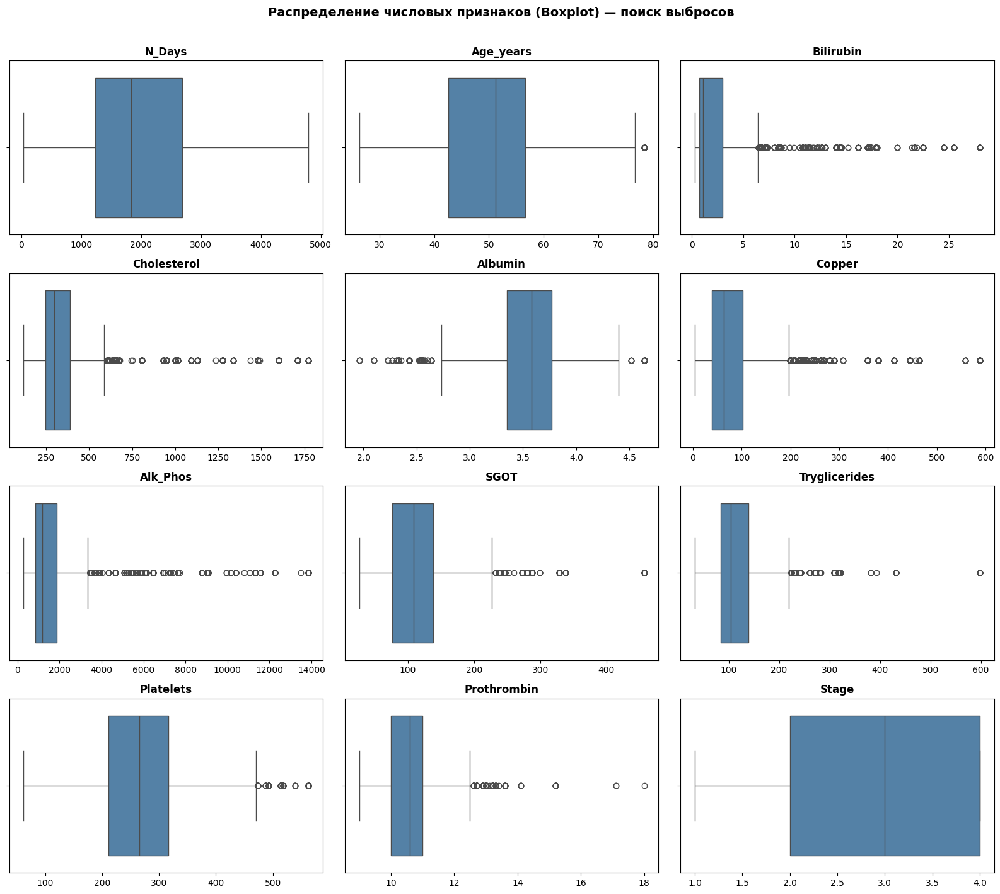

In [16]:
# Основные числовые признаки для анализа выбросов
num_features = ['N_Days', 'Age_years', 'Bilirubin', 'Cholesterol', 'Albumin',
                'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets',
                'Prothrombin', 'Stage']

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.flatten()

for idx, col in enumerate(num_features):
    ax = axes[idx]
    sns.boxplot(x=df[col], ax=ax, color='steelblue')
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel('')

plt.suptitle('Распределение числовых признаков (Boxplot) — поиск выбросов',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


### Анализ boxplot

| Признак | Что видно | Интерпретация |
|---------|-----------|---------------|
| `Bilirubin`, `Copper`, `Alk_Phos`, `SGOT` | Правый «хвост» и единичные точки | Клинически реальные тяжёлые пациенты, не ошибки |
| `N_Days` | Правый хвост до ~4800 дней | Длительное наблюдение без события — штатно для survival-данных |
| `Platelets`, `Albumin` | Левый хвост | Тромбоцитопения и гипоальбуминемия — типичны при циррозе |

> **Вывод:** формальные IQR-выбросы в этом датасете — не мусор, а тяжёлые пациенты. Прямое удаление по правилу 1.5·IQR недопустимо, корректнее — log-преобразование (см. 2.5).

## **3.3 Проверка аномальных значений**

In [17]:
# Гарантируем, что id — обычная колонка
if 'id' not in df.columns:
    df = df.reset_index()

# Колонки, реально присутствующие в датафрейме (защита от опечаток)
available_cols = set(df.columns)

def cols_present(cols):
    return [c for c in cols if c in available_cols]

def check_anomaly(mask, title, cols=None):
    subset = df[mask]
    print(f"{title}: {len(subset)}")
    if len(subset) > 0:
        cols_use = cols_present(cols) if cols else None
        display(subset if cols_use is None else subset[cols_use])
    print('-' * 60)

# 1. Нулевые и отрицательные значения лабораторных показателей
check_anomaly(df['Bilirubin'] == 0, "Пациенты с Bilirubin = 0")
check_anomaly(df['Albumin'] == 0, "Пациенты с Albumin = 0")
check_anomaly(df['Platelets'] == 0, "Пациенты с Platelets = 0")
check_anomaly(df['Prothrombin'] == 0, "Пациенты с Prothrombin = 0")
check_anomaly(df['Cholesterol'] == 0, "Пациенты с Cholesterol = 0")
check_anomaly(df['Tryglicerides'] <= 0, "Пациенты с Tryglicerides <= 0")

# 2. Несоответствие возрастного диапазона исследования
check_anomaly(df['Age'] < 6570, "Пациенты младше 18 лет (Age < 6570 дней)")

# 3. Аномальные значения времени наблюдения
check_anomaly(df['N_Days'] == 0, "Пациенты с N_Days = 0")

# 4. Некорректные значения Stage
check_anomaly(~df['Stage'].isin([1, 2, 3, 4]), "Пациенты со Stage вне {1, 2, 3, 4}")

# 5. Клинически экстремальные значения
check_anomaly(df['Bilirubin'] > 20,
              "Пациенты с Bilirubin > 20 (тяжёлая желтуха)",
              cols=['id', 'Bilirubin', 'Albumin', 'Stage', 'Status'])
check_anomaly(df['Alk_Phos'] > 10000,
              "Пациенты с Alk_Phos > 10000",
              cols=['id', 'Alk_Phos', 'Bilirubin', 'Stage', 'Status'])
check_anomaly(df['SGOT'] > 1000,
              "Пациенты с SGOT > 1000",
              cols=['id', 'SGOT', 'Bilirubin', 'Stage', 'Status'])
check_anomaly(df['Copper'] > 500,
              "Пациенты с Copper > 500",
              cols=['id', 'Copper', 'Bilirubin', 'Stage', 'Status'])

# 6. Пропуски
print("Пропуски в данных:", df.isna().sum().sum(), "значений")


Пациенты с Bilirubin = 0: 0
------------------------------------------------------------
Пациенты с Albumin = 0: 0
------------------------------------------------------------
Пациенты с Platelets = 0: 0
------------------------------------------------------------
Пациенты с Prothrombin = 0: 0
------------------------------------------------------------
Пациенты с Cholesterol = 0: 0
------------------------------------------------------------
Пациенты с Tryglicerides <= 0: 0
------------------------------------------------------------
Пациенты младше 18 лет (Age < 6570 дней): 0
------------------------------------------------------------
Пациенты с N_Days = 0: 0
------------------------------------------------------------
Пациенты со Stage вне {1, 2, 3, 4}: 0
------------------------------------------------------------
Пациенты с Bilirubin > 20 (тяжёлая желтуха): 79


,id,Bilirubin,Albumin,Stage,Status
29,29,28.0,3.26,3.0,D
213,213,22.5,3.31,2.0,D
284,284,22.5,3.20,4.0,D
288,288,21.6,3.31,3.0,D
308,308,21.6,3.93,4.0,D
...,...,...,...,...,...
7287,7287,21.9,3.51,4.0,D
7572,7572,24.5,3.18,2.0,D
7585,7585,25.5,3.52,4.0,D
7740,7740,22.5,3.34,4.0,D


------------------------------------------------------------
Пациенты с Alk_Phos > 10000: 114


,id,Alk_Phos,Bilirubin,Stage,Status
105,105,10396.799805,5.5,2.0,C
420,420,10165.000000,1.1,2.0,C
447,447,11046.599609,1.1,3.0,C
465,465,12258.799805,3.3,4.0,C
482,482,11552.000000,3.2,3.0,CL
...,...,...,...,...,...
7407,7407,11046.599609,5.1,4.0,D
7425,7425,13862.400391,1.3,3.0,C
7540,7540,12258.799805,1.8,3.0,D
7729,7729,12258.799805,0.8,3.0,C


------------------------------------------------------------
Пациенты с SGOT > 1000: 0
------------------------------------------------------------
Пациенты с Copper > 500: 26


,id,Copper,Bilirubin,Stage,Status
750,750,588.0,6.600000,4.0,D
961,961,588.0,11.400000,4.0,D
1034,1034,588.0,0.800000,3.0,C
1191,1191,558.0,3.500000,4.0,D
1264,1264,558.0,17.400000,2.0,D
1701,1701,588.0,21.600000,4.0,D
1955,1955,558.0,17.100000,4.0,D
2239,2239,588.0,11.400000,4.0,D
2575,2575,588.0,17.200001,4.0,D
3523,3523,588.0,17.400000,4.0,D


------------------------------------------------------------
Пропуски в данных: 0 значений


## **3.4 Структурные проверки**

Что ловим: опечатки в категориях (`'M '` vs `'M'`), лишние пробелы, неожиданные значения, дубликаты пациентов.

In [18]:
# 1.1 Уникальность id
print("Дубликатов id:", df['id'].duplicated().sum())

# 1.2 Полные дубликаты строк
print("Полных дубликатов строк:", df.duplicated().sum())

# 1.3 Типы данных
print(df.dtypes)

# 1.4 Пропуски
print(df.isna().sum())

# 1.5 Уникальные значения категориальных признаков
for c in ['Drug', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Status']:
    print(f"{c}: {df[c].unique()}  (n={df[c].nunique()})")

# 1.6 Stage как порядковая
print("Stage:", sorted(df['Stage'].unique()))


Дубликатов id: 0
Полных дубликатов строк: 0
id                      int64
N_Days                  int16
Drug                 category
Age                     int16
Sex                  category
Ascites              category
Hepatomegaly         category
Spiders              category
Edema                category
Bilirubin             float32
Cholesterol           float32
Albumin               float32
Copper                float32
Alk_Phos              float32
SGOT                  float32
Tryglicerides         float32
Platelets             float32
Prothrombin           float32
Stage                 float32
Status               category
Age_years             float64
Edema_num             float32
is_severe                int8
is_dead                  int8
log_Bilirubin         float32
log_Copper            float32
log_Alk_Phos          float32
log_SGOT              float32
log_Cholesterol       float32
log_Tryglicerides     float32
Sex_M                    int8
Ascites_Y                i

## **3.5 Медицинские границы**

Что ловим: нулевые/отрицательные значения, опечатки на порядок (например, `Alk_Phos = 13862.4` при норме до ~120), пациентов вне возрастного диапазона исследования.

In [19]:
# 2.1 Биологически невозможные значения
checks = {
    'Bilirubin':       (df['Bilirubin'] <= 0).sum(),
    'Cholesterol':     (df['Cholesterol'] <= 0).sum(),
    'Albumin':         (df['Albumin'] <= 0).sum(),
    'Copper':          (df['Copper'] <= 0).sum(),
    'Alk_Phos':        (df['Alk_Phos'] <= 0).sum(),
    'SGOT':            (df['SGOT'] <= 0).sum(),
    'Tryglicerides':   (df['Tryglicerides'] <= 0).sum(),
    'Platelets':       (df['Platelets'] <= 0).sum(),
    'Prothrombin':     (df['Prothrombin'] <= 0).sum(),
    'Age':             (df['Age'] <= 0).sum(),
    'N_Days':          (df['N_Days'] < 0).sum(),
}
print(pd.Series(checks, name='кол-во аномалий'))

# 2.2 Клинически допустимые диапазоны
ranges = {
    'Bilirubin':    (0.1, 30),
    'Albumin':      (1.5, 6),
    'Prothrombin':  (8, 20),
    'Platelets':    (50, 600),
    'Age':          (18*365, 100*365),  # дни
}
for col, (lo, hi) in ranges.items():
    out = ((df[col] < lo) | (df[col] > hi)).sum()
    print(f"{col}: вне [{lo}, {hi}] -> {out}")


Bilirubin        0
Cholesterol      0
Albumin          0
Copper           0
Alk_Phos         0
SGOT             0
Tryglicerides    0
Platelets        0
Prothrombin      0
Age              0
N_Days           0
Name: кол-во аномалий, dtype: int64
Bilirubin: вне [0.1, 30] -> 0
Albumin: вне [1.5, 6] -> 0
Prothrombin: вне [8, 20] -> 0
Platelets: вне [50, 600] -> 0
Age: вне [6570, 36500] -> 0


## **3.6 Согласованность категориальных и клинических признаков**

Что ловим: опечатки в категориях (`'y'`, `'Yes'`), несовместимые сочетания (лёгкий Stage с признаками тяжёлой декомпенсации), которые могут быть ошибками ввода.

In [20]:
# 3.1 Ascites / Hepatomegaly / Spiders должны быть {N, Y}
for c in ['Ascites', 'Hepatomegaly', 'Spiders']:
    bad = (~df[c].isin(['N', 'Y'])).sum()
    print(f"{c}: некорректных значений = {bad}")

# Edema имеет три уровня: {N, S, Y}
print("Edema:", df['Edema'].value_counts().to_dict())

# 3.2 Status — только {C, D, CL}
print("Status:", df['Status'].value_counts().to_dict())

# 3.3 Stage — только {1, 2, 3, 4}
print("Stage:", df['Stage'].value_counts().sort_index().to_dict())

# 3.4 Клиническая согласованность: тяжёлый асцит (Edema='Y'/'S') при нормальном Albumin
print("Edema=Y/S с Albumin > 3.5:",
      ((df['Edema'].isin(['Y', 'S'])) & (df['Albumin'] > 3.5)).sum())

# 3.5 Stage 4 vs Bilirubin (в среднем должно быть выше на поздних стадиях)
print(df.groupby('Stage')['Bilirubin'].agg(['mean', 'median', 'count']))


Ascites: некорректных значений = 0
Hepatomegaly: некорректных значений = 0
Spiders: некорректных значений = 0
Edema: {'N': 7161, 'S': 399, 'Y': 345}
Status: {'C': 4965, 'D': 2665, 'CL': 275}
Stage: {1.0: 397, 2.0: 1652, 3.0: 3153, 4.0: 2703}
Edema=Y/S с Albumin > 3.5: 242
           mean  median  count
Stage                         
1.0    1.449874     0.8    397
2.0    1.827845     0.9   1652
3.0    2.172598     0.9   3153
4.0    3.723270     2.0   2703


## **3.7 Статистические выбросы (IQR / z-score / MAD)**

Что ловим: формальные выбросы. **Важно:** в этом датасете большинство «выбросов» — клинически реальные тяжёлые пациенты, а не ошибки ввода.

In [21]:
num_cols = ['N_Days', 'Age', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper',
            'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin']

# 4.1 IQR-выбросы
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()

print(df[num_cols].apply(iqr_outliers).sort_values(ascending=False))

# 4.2 z-score > 3
z = np.abs(stats.zscore(df[num_cols], nan_policy='omit'))
print((z > 3).sum(axis=0))

# 4.3 Модифицированный z-score (MAD) — устойчивее к выбросам
def mad_outliers(s):
    med = s.median()
    mad = (s - med).abs().median()
    if mad == 0:
        return 0
    return ((0.6745 * (s - med) / mad).abs() > 3.5).sum()

print(df[num_cols].apply(mad_outliers))


Alk_Phos         792
Bilirubin        789
Copper           655
Cholesterol      502
Tryglicerides    267
Albumin          178
Prothrombin      173
SGOT             146
Platelets        114
Age               36
N_Days             0
dtype: int64
[  0   0 281 216 106 151 189  80 113  41 113]
N_Days              0
Age                 0
Bilirubin        1312
Cholesterol       426
Albumin            86
Copper            655
Alk_Phos          744
SGOT               80
Tryglicerides     143
Platelets          36
Prothrombin        67
dtype: int64


## **3.8 Проверка распределений**

Что ловим: сильную скошенность (`Bilirubin`, `Copper`, `Alk_Phos`, `SGOT`) — сигнал к log1p-преобразованию перед моделированием (уже сделано в блоке 2.5).

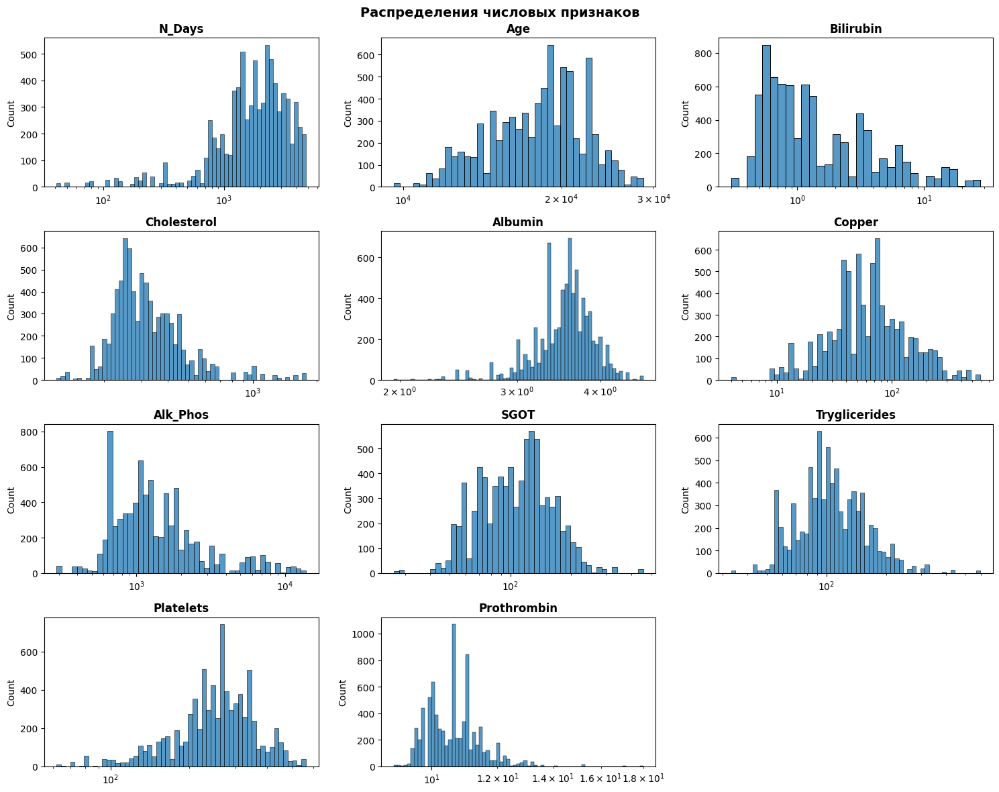

In [22]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))

for ax, c in zip(axes.flatten(), num_cols):
    use_log = bool(df[c].min() > 0)  # приводим к чистому bool
    sns.histplot(
        df[c],
        kde=not use_log,             # KDE плохо работает на лог-шкале
        ax=ax,
        log_scale=use_log if use_log else False,
    )
    ax.set_title(c, fontsize=12, fontweight='bold')
    ax.set_xlabel('')

# Если признаков меньше, чем ячеек — скрываем пустые
for ax in axes.flatten()[len(num_cols):]:
    ax.set_visible(False)

plt.suptitle('Распределения числовых признаков', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## **3.9 Странные multivariate-комбинации**

Что ловим: подозрительные сочетания, которые могут быть ошибками ввода (например, перепутаны единицы измерения у конкретного пациента).

In [23]:
# 6.1 Очень высокий Alk_Phos + нормальный Bilirubin (необычно при циррозе)
mask = (df['Alk_Phos'] > 5000) & (df['Bilirubin'] < 1.5)
print("Alk_Phos > 5000 и Bilirubin < 1.5:", mask.sum())
display(df.loc[mask, ['id', 'Alk_Phos', 'Bilirubin', 'Stage', 'Status']])

# 6.2 Очень высокий SGOT при нормальном Bilirubin
mask = (df['SGOT'] > 200) & (df['Bilirubin'] < 1.0)
print("SGOT > 200 и Bilirubin < 1:", mask.sum())

# 6.3 Плохой Prothrombin при статусе C (цензурирован)
mask = (df['Prothrombin'] >= 14) & (df['Status'] == 'C')
print("Prothrombin >= 14 при Status=C:", mask.sum())


Alk_Phos > 5000 и Bilirubin < 1.5: 357


,id,Alk_Phos,Bilirubin,Stage,Status
5,5,6456.200195,0.6,3.0,D
53,53,5430.200195,1.1,3.0,C
120,120,7277.000000,0.6,3.0,C
125,125,5833.000000,0.8,3.0,D
137,137,9066.799805,0.7,4.0,D
...,...,...,...,...,...
7784,7784,12258.799805,1.3,1.0,C
7837,7837,6121.799805,0.7,4.0,D
7841,7841,7277.000000,0.7,4.0,C
7850,7850,5430.200195,0.8,3.0,C


SGOT > 200 и Bilirubin < 1: 61
Prothrombin >= 14 при Status=C: 5


## **3.10 Целевая переменная и период наблюдения**

Здесь проверяем две вещи: равновелики ли классы цели (от этого зависит выбор метрик и способ разбиения данных) и что собой представляет столбец `N_Days` — период наблюдения.

Вопрос про период не формальный. В датасете он выглядит как обычный признак: заполнен у всех пациентов, сильно связан с целью. Но у него особая природа — он измеряет время **до** завершения наблюдения, то есть становится известен только тогда, когда исход уже наступил. Разберём это отдельно и решим, можно ли использовать период при предсказании статуса.

In [24]:
# 1. Баланс классов целевой переменной
balance = pd.DataFrame({
    'пациентов': df['Status'].value_counts(),
    'доля': (df['Status'].value_counts(normalize=True) * 100).round(1),
})
balance.index.name = 'исход'
print('Распределение целевой переменной Status:')
display(balance)
print('Самый редкий класс встречается в',
      int(df['Status'].value_counts().max() // df['Status'].value_counts().min()),
      'раза реже самого частого.')

# 2. Период наблюдения — общее распределение
print('\nПериод наблюдения N_Days (в днях):')
display(df['N_Days'].describe(percentiles=[.05, .25, .5, .75, .95]).round(0).to_frame('значение'))
print(f'В годах: от {df["N_Days"].min() / 365.25:.1f} до {df["N_Days"].max() / 365.25:.1f} лет')
print('Доля наблюдений короче 100 дней:', f'{(df["N_Days"] < 100).mean():.4f}')

# 3. Период в разрезе исходов
print('\nПериод наблюдения по классам цели:')
display(df.groupby('Status', observed=True)['N_Days']
        .agg(['count', 'mean', 'median', 'min', 'max'])
        .round(0)
        .rename(columns={'count': 'пациентов', 'mean': 'средний', 'median': 'медиана',
                         'min': 'минимум', 'max': 'максимум'}))

# 4. Стадия против исхода (проверка клинической согласованности)
print('\nДоли исходов внутри каждой стадии:')
display((pd.crosstab(df['Stage'], df['Status'], normalize='index') * 100).round(1))

Распределение целевой переменной Status:


,пациентов,доля
исход,,
C,4965,62.8
D,2665,33.7
CL,275,3.5


Самый редкий класс встречается в 18 раза реже самого частого.

Период наблюдения N_Days (в днях):


,значение
count,7905.0
mean,2030.0
std,1094.0
min,41.0
5%,334.0
25%,1230.0
50%,1831.0
75%,2689.0
95%,4127.0
max,4795.0


В годах: от 0.1 до 13.1 лет
Доля наблюдений короче 100 дней: 0.0083

Период наблюдения по классам цели:


,пациентов,средний,медиана,минимум,максимум
Status,,,,,
C,4965,2323.0,2216.0,41,4795
CL,275,1610.0,1435.0,131,4453
D,2665,1529.0,1216.0,41,4795



Доли исходов внутри каждой стадии:


Status,C,CL,D
Stage,,,
1.0,88.4,1.8,9.8
2.0,78.3,2.8,18.9
3.0,72.9,3.6,23.5
4.0,37.8,4.0,58.2


### Период наблюдения: причина или следствие?

Судя по таблице выше, связь есть и она сильная: у умерших медиана периода 1 216 дней, у выживших — 2 216. Возникает соблазн использовать период как признак.

Но направление этой связи обратное ожидаемому. **Период не влияет на исход — исход определяет период.** Пациент, умерший на 400-й день, имеет период 400 дней именно потому, что умер; он физически не мог наблюдаться дольше. Период — это запись факта «как долго мы видели этого пациента до развязки», то есть часть ответа на наш вопрос, а не подсказка.

Проверим рассуждение двумя способами.

**Мысленный эксперимент, предложенный как часть постановки задачи.** Представим, что мы «вытянули» всех пациентов до максимального периода — 4 795 дней (13.1 года), как если бы наблюдение никогда не прерывалось. Статус ни у кого от этого не изменился бы: умерший остаётся умершим, перенёсший трансплантацию — перенёсшим. Если бы период был причиной исхода, выравнивание периода должно было бы выровнять и исходы. Оно не может этого сделать, потому что период наступил **после** решения задачи.

**Проверка на данных.** Если период не определяет исход, то у пациентов с одинаковым периодом должны встречаться все три исхода. Так и есть: в узком коридоре 1 216 ± 30 дней (это ровно медиана умерших) около четверти пациентов живы. И наоборот: один и тот же исход даёт совершенно разный период — у умерших разброс от 140 до 3 820 дней, разница в 27 раз.

In [25]:
# 1. Мысленный эксперимент: приравняем период к максимальному у всех пациентов.
#    Спросим: изменился бы от этого статус? Нет — статус нам дан, мы только
#    смотрим, что происходит с распределением периода.
mx = df['N_Days'].max()
df_shifted = df.copy()
df_shifted['N_Days'] = mx
print(f'Эксперимент: ставим всем период = {mx} дней ({mx / 365.25:.1f} лет)')
print('Исходы после выравнивания периода:')
display(df_shifted['Status'].value_counts(normalize=True).mul(100).round(1)
        .rename('доля, %').to_frame())
print('=> Распределение исходов не изменилось ни на одного пациента:')
print('   период — величина подчинённая, он не участвует в формировании статуса.\n')

# 2. Один и тот же период — разные исходы?
print('Исходы среди пациентов с одинаковым периодом (коридор +/- 30 дней):')
rows = []
for d in [1216, 1831, 2216, 3000]:
    band = df[(df['N_Days'] >= d - 30) & (df['N_Days'] <= d + 30)]
    share = band['Status'].value_counts(normalize=True).mul(100).round(1)
    rows.append({'период, дней': d, 'пациентов': len(band),
                 'живы, %': share.get('C', 0.0),
                 'трансплантация, %': share.get('CL', 0.0),
                 'умерли, %': share.get('D', 0.0)})
display(pd.DataFrame(rows).set_index('период, дней'))
print('=> При одном и том же периоде около четверти пациентов умирают и около')
print('   70 % живы. Период не задаёт исход.\n')

# 3. Обратная задача: один исход — разный период?
for s, label in [('C', 'выжившие'), ('D', 'умершие')]:
    g = df.loc[df['Status'] == s, 'N_Days']
    p5, p95 = g.quantile(.05), g.quantile(.95)
    print(f'{label}: 90 % наблюдений в интервале {p5:.0f}..{p95:.0f} дней '
          f'(разница в {p95 / p5:.1f} раза)')
d_above = (df.loc[df['Status'] == 'D', 'N_Days'] > df.loc[df['Status'] == 'C', 'N_Days'].median()).mean()
print(f'=> {d_above:.1%} умерших наблюдались дольше медианы выживших: классы по периоду')
print('   не разделяются, а сильно перекрываются.')

Эксперимент: ставим всем период = 4795 дней (13.1 лет)
Исходы после выравнивания периода:


,"доля, %"
Status,
C,62.8
D,33.7
CL,3.5


=> Распределение исходов не изменилось ни на одного пациента:
   период — величина подчинённая, он не участвует в формировании статуса.

Исходы среди пациентов с одинаковым периодом (коридор +/- 30 дней):


,пациентов,"живы, %","трансплантация, %","умерли, %"
"период, дней",,,,
1216,303,70.6,4.0,25.4
1831,99,71.7,3.0,25.3
2216,139,73.4,5.8,20.9
3000,63,88.9,0.0,11.1


=> При одном и том же периоде около четверти пациентов умирают и около
   70 % живы. Период не задаёт исход.

выжившие: 90 % наблюдений в интервале 999..4196 дней (разница в 4.2 раза)
умершие: 90 % наблюдений в интервале 140..3820 дней (разница в 27.3 раза)
=> 26.8% умерших наблюдались дольше медианы выживших: классы по периоду
   не разделяются, а сильно перекрываются.


### Можно ли использовать период вторым шагом: сначала статус, потом период

Раз период — следствие исхода, возникает идея построить двухэтапную модель: на первом шаге предсказать статус по клиническим данным, на втором — зная (предсказанный) статус, предсказать период. Тогда причинная цепочка соблюдена: сначала причина, потом следствие.

Идея верна методологически, но её полезность надо измерить. Проверим, насколько вообще предсказуем период по имеющимся данным.

In [26]:
# Насколько вообще предсказуем период по клиническим данным?
# Оценка — на пяти частях данных (кросс-валидация), чтобы не подглядывать в проверку.
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

CLIN = ['log_Bilirubin', 'log_Copper', 'log_Alk_Phos', 'log_SGOT', 'log_Cholesterol',
        'log_Tryglicerides', 'Albumin', 'Platelets', 'Prothrombin', 'Age_years',
        'Stage', 'Edema_num', 'Sex_M', 'Ascites_Y', 'Hepatomegaly_Y', 'Spiders_Y']

X_nd = df[CLIN].astype(float)
y_nd = df['N_Days'].astype(float)
r2_clinical = cross_val_score(LinearRegression(), X_nd, y_nd, cv=5, scoring='r2').mean()

# Тот же опыт, но со статусом как дополнительным столбцом (он «уже известен»)
X2 = X_nd.copy()
for s in ['C', 'CL', 'D']:
    X2[f'status_{s}'] = (df['Status'] == s).astype(int)
r2_with_status = cross_val_score(LinearRegression(), X2, y_nd, cv=5, scoring='r2').mean()

print(f'Доля объяснённого разброса периода по клиническим признакам: {r2_clinical:.3f}')
print(f'То же с добавлением статуса:                                  {r2_with_status:.3f}')
print(f'Прирост от знания статуса: {r2_with_status - r2_clinical:+.3f}')

Доля объяснённого разброса периода по клиническим признакам: 0.225
То же с добавлением статуса:                                  0.234
Прирост от знания статуса: +0.008


**Результат проверки.** Период объясняется клиническими признаками слабо: доля объяснённого разброса составляет **0.22**. То есть 78 % разброса периода остаётся необъяснённым — им управляют факторы, которых в датасете нет (случайность момента обращения, доступность трансплантата, сопутствующие болезни, выход пациента из-под наблюдения).

Второе число важнее. Если подставить в ту же модель **уже известный** статус, доля объяснённого разброса вырастает лишь до **0.23** — на 0.008. Знание ответа на главный вопрос задачи почти не помогает ответить на второй. Практический смысл: двухэтапная схема не даёт выигрыша, который оправдал бы удвоение сложности.

### Решение по периоду наблюдения

| Вариант | Что это | Оценка | Решение |
|---|---|---|---|
| Использовать период как признак статуса | модель получает время до развязки в качестве подсказки | качество почти не меняется (стадия 3: доля верных ответов 0.796 против 0.795), но смысл подмены раскрывается при проверке на новых пациентах | **не используем** |
| Двухэтапная схема: статус, затем период | предсказание периода по известному статусу | период объясняется на 22 %, добавление статуса улучшает до 23 % | **не делаем**: выигрыша нет |
| Не работать с периодом в задаче классификации | период остаётся объектом отдельного анализа | — | **выбранный вариант** |

Период не удаляем из файла данных: он нужен для анализа выживаемости (кривые выживаемости Kaplan-Meier в блоке 4.9) и для проверки корректности очистки. Но в матрицу признаков моделей стадий 2 и 3 он не входит, и в стаде 3 это решение проверяется контрольным опытом с числами.

**Почему это решение важно зафиксировать.** Если бы период остался в модели, метрики выглядели бы чуть лучше, а на реальной врачебной задаче («каков прогноз пациента, поступающего сегодня?») модель оказалась бы бесполезна: у нового пациента период ещё не известен и взять его неоткуда.

## **3.11 Drug vs Placebo (дизайн исследования)**

Что ловим: нарушение рандомизации, дисбаланс групп — важно для интерпретации причинного эффекта препарата.

In [27]:
# 8.1 Сбалансированность групп
print(df['Drug'].value_counts())
print(pd.crosstab(df['Drug'], df['Status']))

# 8.2 Сравнение базовых характеристик (должны быть похожи при рандомизации)
df.groupby('Drug')[['Age', 'Bilirubin', 'Albumin', 'Platelets']].mean()


Drug
Placebo            4010
D-penicillamine    3895
Name: count, dtype: int64
Status              C   CL     D
Drug                            
D-penicillamine  2405  151  1339
Placebo          2560  124  1326


/tmp/ipykernel_366775/783762329.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('Drug')[['Age', 'Bilirubin', 'Albumin', 'Platelets']].mean()


,Age,Bilirubin,Albumin,Platelets
Drug,,,,
D-penicillamine,18716.898331,2.450218,3.537759,263.527344
Placebo,18039.252868,2.734613,3.558583,266.881805


## **3.12 Взаимная близость признаков (перед моделированием)**

**Зачем это нужно.** Линейная модель складывает признаки с весами. Если два признака почти повторяют друг друга, модель не может разделить их вклад: один вес может оказаться большим положительным, другой — большим отрицательным, хотя по отдельности оба признака связаны с исходом одинаково. В итоге веса нестабильны, а объяснение модели теряет смысл. Такое явление называют мультиколлинеарностью.

**Что считаем и на каких данных.** Считаем попарные корреляции по **итоговому** набору признаков — тому, который пойдёт в модель после правила «одна информация — один столбец» из блока 2.5. Это принципиально: на исходных данных картина искажена искусственными копиями (показатель и его логарифм), и половина «страшных» пар оказалась бы дубликатами, созданными нами же.

**Порог.** Считаем тревожными пары с корреляцией по модулю выше **0.6**. Классический порог 0.8 здесь слишком слаб: после удаления дубликатов таких пар не остаётся вообще, и проверка ничего не проверяет. Порог 0.6 оставляет осмысленный критерий отбора.

**Как принимаем решение при обнаружении пары.** Не удаляем «второй попавшийся» признак. Проверяем на данных, какой из двух даёт модели больше, и оставляем один. Если качество от удаления не падает — удаляем: более простая модель надёжнее и легче объясняется.

Признаков в итоговом наборе (до отбора по близости): 16


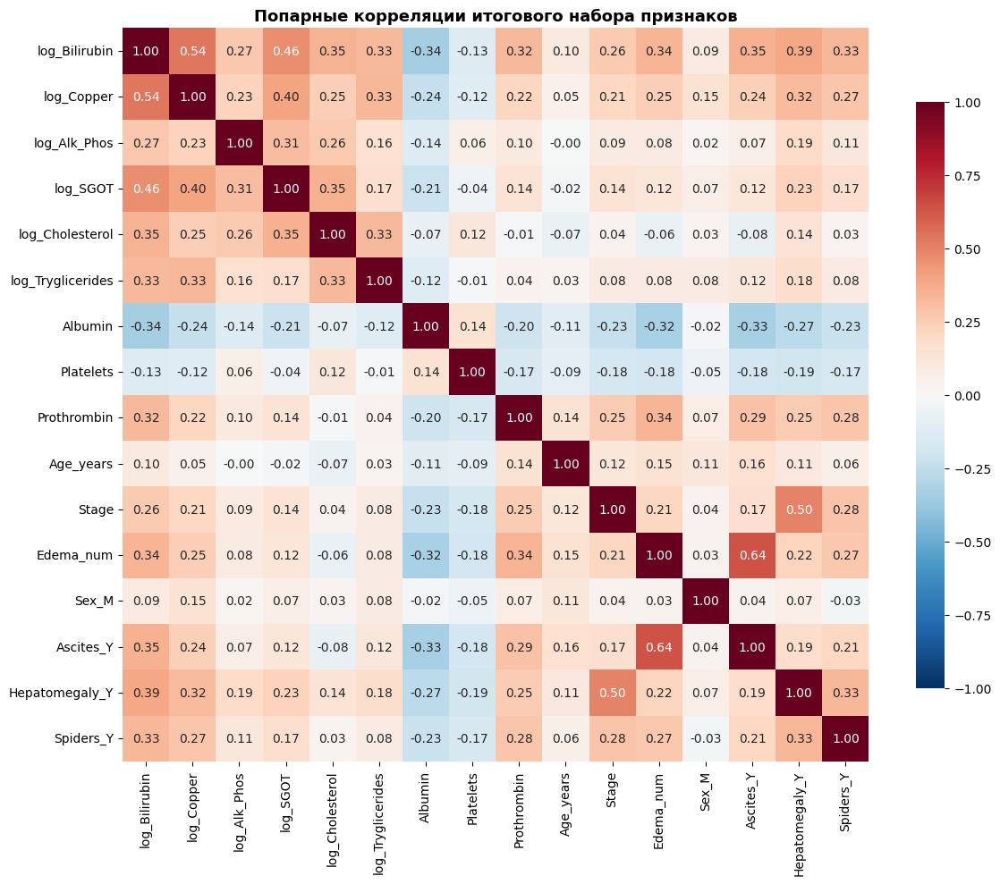

Пар с корреляцией выше 0.8: 0
Пар с корреляцией выше 0.6: 1


,,корреляция
Edema_num,Ascites_Y,0.635



Сильнейшая пара — отёки и асцит. Оба признака описывают задержку жидкости,
поэтому сильная связь клинически ожидаема: при тяжёлом асците отёки почти всегда есть.


In [28]:
# Итоговый набор признаков: по одному представителю каждой пары (правило блока 2.5)
MODEL_NUM = ['log_Bilirubin', 'log_Copper', 'log_Alk_Phos', 'log_SGOT',
             'log_Cholesterol', 'log_Tryglicerides',
             'Albumin', 'Platelets', 'Prothrombin',
             'Age_years', 'Stage', 'Edema_num',
             'Sex_M', 'Ascites_Y', 'Hepatomegaly_Y', 'Spiders_Y']

X_model = df[MODEL_NUM].astype(float)
print(f'Признаков в итоговом наборе (до отбора по близости): {X_model.shape[1]}')

corr = X_model.corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Попарные корреляции итогового набора признаков', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Пары выше порога 0.6
UPPER = np.triu(np.ones_like(corr, dtype=bool), k=1)
pairs = corr.where(UPPER).stack().sort_values(key=abs, ascending=False)
strong = pairs[pairs.abs() > 0.6]

print(f'Пар с корреляцией выше 0.8: {int((pairs.abs() > 0.8).sum())}')
print(f'Пар с корреляцией выше 0.6: {len(strong)}')
display(strong.abs().round(3).rename('корреляция').to_frame())

print('\nСильнейшая пара — отёки и асцит. Оба признака описывают задержку жидкости,')
print('поэтому сильная связь клинически ожидаема: при тяжёлом асците отёки почти всегда есть.')

### Что делать с парой «асцит — отёки»

Один признак из пары надо убрать. Чтобы не решать это «на глаз», сравним три набора на кросс-валидации. Кросс-валидация — это честная проверка: данные делятся на пять частей, модель пять раз обучается на четырёх частях и проверяется на пятой, причём каждый пациент побывает в проверке ровно один раз. Одна цифра на одном разбиении может случайно получиться лучше, а среднее по пяти частям с разбросом показывает реальную картину.

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y_status = df['Status'].astype(str)

# Масштабирование вшито в конвейер, чтобы обучать его только на обучаемой части —
# иначе статистика проверка «просочилась» бы в обучение и оценка стала бы оптимистичной
pipeline = lambda: make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)
)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

variants = {
    'A: оба признака (асцит + отёки)': MODEL_NUM,
    'B: без асцита (отёки остаются)':  [c for c in MODEL_NUM if c != 'Ascites_Y'],
    'C: без отёков (асцит остаётся)':  [c for c in MODEL_NUM if c != 'Edema_num'],
}

rows = []
for tag, cols in variants.items():
    X = df[cols].astype(float)
    acc = cross_val_score(pipeline(), X, y_status, cv=folds, scoring='accuracy')
    f1 = cross_val_score(pipeline(), X, y_status, cv=folds, scoring='f1_macro')
    ll = -cross_val_score(pipeline(), X, y_status, cv=folds, scoring='neg_log_loss')
    rows.append({'набор': tag, 'признаков': len(cols),
                 'доля верных ответов': acc.mean(), 'разброс по частям': acc.std(),
                 'F-мера (среднее по классам)': f1.mean(),
                 'логарифмическая потеря': ll.mean()})

comparison = pd.DataFrame(rows).set_index('набор')
display(comparison.round(4))

spread = comparison.loc['A: оба признака (асцит + отёки)', 'разброс по частям']
drop_a = abs(comparison.loc['A: оба признака (асцит + отёки)', 'доля верных ответов']
             - comparison.loc['B: без асцита (отёки остаются)', 'доля верных ответов'])
drop_c = comparison.loc['A: оба признака (асцит + отёки)', 'доля верных ответов'] \
         - comparison.loc['C: без отёков (асцит остаётся)', 'доля верных ответов']

print(f'\nРазница между A и B (асцит лишний): {drop_a:.4f} при разбросе по частям ±{spread:.4f}')
print('=> Разница много меньше разброса — это шум, а не эффект. Асцит можно убрать.')
print(f'Разница между A и C (отёки лишние): {drop_c:.4f} — набор C хуже по всем метрикам,')
print('   значит отёки несут больше информации об исходе, чем асцит.')
print('\nРЕШЕНИЕ: убираем Ascites_Y, оставляем Edema_num. Итоговый набор — 15 признаков.')

,признаков,доля верных ответов,разброс по частям,F-мера (среднее по классам),логарифмическая потеря
набор,,,,,
A: оба признака (асцит + отёки),16,0.8000,0.0070,0.5268,0.5214
B: без асцита (отёки остаются),15,0.7997,0.0069,0.5266,0.5212
C: без отёков (асцит остаётся),15,0.7958,0.0044,0.5237,0.5253



Разница между A и B (асцит лишний): 0.0003 при разбросе по частям ±0.0070
=> Разница много меньше разброса — это шум, а не эффект. Асцит можно убрать.
Разница между A и C (отёки лишние): 0.0042 — набор C хуже по всем метрикам,
   значит отёки несут больше информации об исходе, чем асцит.

РЕШЕНИЕ: убираем Ascites_Y, оставляем Edema_num. Итоговый набор — 15 признаков.


## **3.13 Неинформативные признаки**

Что ловим: колонки, которые не несут информации для модели — константные, технические, с нулевой или почти нулевой связью с целью.

**Четыре меры оценки:**

| Мера | Для чего | Как интерпретировать |
|------|----------|---------------------|
| Доля модального значения | Почти константные признаки | > 90 % — признак почти не меняется, модель нечему учиться |
| φk (phik) с `Status` | Связь любого типа (число ↔ категория) | < 0.1 — практически нет связи |
| Mutual information | Нелинейная зависимость от цели | ≈ 0 — нет информационной зависимости |
| Cramér's V + χ²-тест | Категориальные признаки | V < 0.1 и p > 0.05 — нет статистически значимой связи |
| Kruskal-Wallis H + p | Числовые признаки | p > 0.05 — распределения по классам не различаются |

Правило отбора: признак исключается, если φk < 0.1 и (V < 0.1 и p > 0.05 для категориальных, либо p > 0.05 для числовых). p-value используется как дополнительный фильтр: при n = 7 905 почти любой ненулевой эффект статистически значим, поэтому решающим является размер эффекта (φk, V).

In [30]:
import warnings

import phik
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder
from scipy.stats import chi2_contingency, kruskal

y = df['Status']
X = df.drop(columns=['Status', 'id']).copy()

cat_cols = [c for c in X.columns if X[c].dtype in ('object', 'category')]
num_cols = [c for c in X.columns if c not in cat_cols]

# Мера 1. Доля модального значения (проверка на почти константные)
nunique = df.nunique()
print('Признаки с <= 2 уникальными значениями:')
print(nunique[nunique <= 2].to_string())

# Мера 2. φk с целью
pk = df[cat_cols + num_cols + ['Status']].phik_matrix(
    interval_cols=num_cols, njobs=1
).loc[cat_cols + num_cols, 'Status']

# Мера 3. Mutual information (цель и категориальные признаки кодируем целыми)
le_y = LabelEncoder()
y_num = le_y.fit_transform(y.astype(str))
X_enc = X.copy()
for c in cat_cols:
    X_enc[c] = LabelEncoder().fit_transform(X_enc[c].astype(str))
X_enc = X_enc.astype(float)
disc = [X[c].nunique() <= 6 for c in X.columns]

with warnings.catch_warnings():
    # sklearn предупреждает о «continuous values for label» — это особенность
    # оценки MI по смешанным типам, на результат не влияет
    warnings.simplefilter('ignore')
    mi = pd.Series(
        mutual_info_classif(X_enc, y_num, discrete_features=disc, random_state=42),
        index=X.columns
    )

# Мера 4. Категориальные — Cramér's V и χ²; числовые — Kruskal-Wallis
cat_stats = {}
for c in cat_cols:
    tab = pd.crosstab(X[c], y)
    chi2, p_chi, dof, _ = chi2_contingency(tab)
    n, r, k = tab.values.sum(), *tab.shape
    cat_stats[c] = {'V': np.sqrt(chi2 / (n * (min(r, k) - 1))), 'p': p_chi}

num_stats = {}
for c in num_cols:
    h, p_h = kruskal(*[X.loc[y == g, c].values for g in ['C', 'CL', 'D']])
    num_stats[c] = {'H': h, 'p': p_h}

# Сводная таблица: сравнимые меры выстроены в параллельные столбцы
rows = []
for c in X.columns:
    rows.append({
        'тип': 'кат.' if c in cat_cols else 'числ.',
        'доля модального': X[c].value_counts(normalize=True).iloc[0],
        'φk(Status)': pk[c],
        'MI': mi[c],
        'Cramér V (кат.)': cat_stats[c]['V'] if c in cat_stats else np.nan,
        'Kruskal H (числ.)': num_stats[c]['H'] if c in num_stats else np.nan,
        'p-значение': cat_stats[c]['p'] if c in cat_stats else num_stats[c]['p'],
    })

tbl = pd.DataFrame(rows, index=X.columns).rename_axis('признак')
# p-значения в научной нотации: при n = 7 905 они мельче 1e-4, обычные 4 знака их не показывают
tbl['p-значение'] = tbl['p-значение'].map(lambda v: f'{v:.1e}')

print('\nМеры связи каждого признака с целью Status (по убыванию φk):')
display(tbl.sort_values('φk(Status)', ascending=False).round(4))

Признаки с <= 2 уникальными значениями:
Drug              2
Sex               2
Ascites           2
Hepatomegaly      2
Spiders           2
is_severe         2
is_dead           2
Sex_M             2
Ascites_Y         2
Hepatomegaly_Y    2
Spiders_Y         2



Меры связи каждого признака с целью Status (по убыванию φk):


,тип,доля модального,φk(Status),MI,Cramér V (кат.),Kruskal H (числ.),p-значение
признак,,,,,,,
is_dead,числ.,0.6629,1.0000,0.6391,NaN,7904.0000,0.0e+00
Copper,числ.,0.0393,0.5978,0.1617,NaN,1525.1876,0.0e+00
log_Bilirubin,числ.,0.1071,0.5630,0.1899,NaN,2326.3363,0.0e+00
Edema,кат.,0.9059,0.5579,0.0595,0.2416,NaN,2.2e-198
Edema_num,числ.,0.9059,0.5579,0.0595,NaN,873.6313,2.0e-190
N_Days,числ.,0.0148,0.5020,0.1877,NaN,1102.8720,3.3e-240
Bilirubin,числ.,0.1071,0.5011,0.1854,NaN,2326.3363,0.0e+00
log_Copper,числ.,0.0393,0.4886,0.1680,NaN,1525.1876,0.0e+00
SGOT,числ.,0.0324,0.4805,0.1429,NaN,929.2786,1.6e-202


### Вывод по отбору признаков

Из 28 исследованных признаков (в сравнение не входят только `id` и цель `Status`) ни один не является константным. Но связь с целью у них очень разная:

| Что проверяем | Меры из таблицы выше | Признак | Решение |
|---|---|---|---|
| Практически нет связи с целью | связь 0.013, взаимная информация 0.0004, теснота связи 0.027 при вероятности 0.053 | `Drug` | **исключить** |
| Технический ключ, а не признак | уникален в 7 905 строках | `id` | **исключить** |
| Прямая утечка цели | связь 1.000 — это половина ответа на вопрос задачи | `is_dead` | **исключить** |
| Редкое значение, но значимая связь | доля 92.8 %, теснота связи 0.131 | `Sex` | оставить |
| Редкое значение, но значимая связь | доля 95.2 %, теснота связи 0.277 | `Ascites` | оставить по этому критерию (исключается в блоке 3.12 как дубль отёков) |
| Почти константный, но сильный предиктор | доля 90.6 %, связь 0.558 | `Edema` | оставить |

**Почему `Drug` уходит, а `Sex` и `Ascites` — нет.** `Drug` — единственный признак, который не проходит проверку по всем мерам сразу: связь с исходом практически нулевая, и статистический тест не отвергает гипотезу о том, что исходы в группах препарата и плацебо распределены одинаково. Доли исходов в группах действительно почти совпадают: в группе плацебо 63.8 % живых, 33.1 % умерших, 3.1 % с трансплантацией; в группе препарата — 61.7 %, 34.4 % и 3.9 %. Различий нет, что заодно подтверждает корректность рандомизации исследования. Для модели это признак-шум.

`Sex` и `Ascites` выглядят как «почти константные» по доле самого частого значения (92.8 % и 95.2 %), но их связь с исходом статистически значима и заметна по размеру. **Главный вывод блока: «редкое значение» и «неинформативный признак» — не одно и то же.** Доля самого частого значения описывает, насколько признак вообще меняется, а не насколько он связан с ответом. Поэтому решение принимается по мерам связи, а не по изменчивости.

### Итог: три основания исключить столбец из модели

К этому месту стадии у нас накопились три независимых проверки, и каждая отсекает своё. Сводим их вместе — получится окончательный список признаков модели.

| Основание исключения | Где показано | Столбцы |
|---|---|---|
| Не связано с исходом или техническое | блок 3.13 | `Drug`, `id` |
| Раскрывает ответ заранее | блок 3.13 | `is_dead` |
| Известно только после наступления исхода | блок 3.10 | `N_Days` |
| Дублирует другой столбец (правило «одна информация — один столбец») | блоки 2.5 и 3.12 | `Bilirubin`, `Copper`, `Alk_Phos`, `SGOT`, `Cholesterol`, `Tryglicerides`, `Age`, `Edema`, `is_severe`, `Ascites` |

**Остаются 15 признаков:** шесть лабораторных показателей в логарифме (билирубин, медь, щелочная фосфатаза, AST, холестерин, триглицериды), три показателя без преобразования (альбумин, тромбоциты, протромбин), возраст в годах, стадия фиброза, порядковый код отёков и три бинарных признака (мужской пол, увеличенная печень, сосудистые «паучки»).

Все отсечённые столбцы остаются в файле `train_clean.parquet` — они нужны для графиков и таблиц этой стадии. Для моделей формируется отдельный файл с чистым набором из 15 признаков, чтобы дубликат или утечка не могли попасть в обучение по случайности.

## **3.14 Очистка данных**

На основе проведённых проверок удаляем только записи, которые противоречат протоколу исследования (клинически невозможные значения). Все «статистические» выбросы сохраняем: это реальные тяжёлые пациенты.

**Правила очистки:**
1. Убираем пациентов с `Bilirubin`, `Albumin`, `Platelets`, `Prothrombin`, `Cholesterol`, `Copper`, `Alk_Phos`, `SGOT`, `Tryglicerides` <= 0 — это биологически невозможные лабораторные значения.
2. Убираем пациентов с `Age < 18 лет` — вне протокола исследования PBC.
3. Убираем `N_Days == 0` — нулевое время наблюдения непригодно для survival-анализа.

In [31]:
before = len(df)

# 1. Лабораторные значения <= 0
lab_cols = ['Bilirubin', 'Albumin', 'Platelets', 'Prothrombin',
            'Cholesterol', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides']
mask_lab_ok = (df[lab_cols] > 0).all(axis=1)

# 2. Возраст в протоколе (>= 18 лет)
mask_age_ok = df['Age'] >= 18 * 365

# 3. Положительное время наблюдения
mask_days_ok = df['N_Days'] > 0

df_clean = df[mask_lab_ok & mask_age_ok & mask_days_ok].copy()

print(f"Размер до очистки: {before}")
print(f"Размер после очистки: {len(df_clean)}")
print(f"Удалено записей: {before - len(df_clean)}")


Размер до очистки: 7905
Размер после очистки: 7905
Удалено записей: 0


### Сохранение результатов

Дальше по тексту ноутбука идёт визуализация на `df_clean`, а за ним — стадии 2 и 3 с моделированием. Сохраняем два файла:

1. **`train_clean.parquet`** — полный артефакт данных: 30 столбцов, включая инженерные признаки и все дубликаты. Он нужен как есть, потому что графики, таблицы и проверки этой стадии обращаются и к исходным, и к производным вариантам одного и того же показателя.

2. **`train_model.parquet`** — матрица из 15 признаков модели плюс целевая переменная. Именно её читают стадии 2 и 3.

Разделение на два файла снимает риск, что дублированный или неинформативный признак попадёт в модель из-за невнимательности при подготовке данных: в модельной матрице их нет физически. Список признаков задаётся один раз здесь и ниже только проверяется.

Формат Parquet бинарный, сохраняет типы столбцов и не требует повторного прохождения очистки.

In [32]:
# Итоговый список признаков модели (обоснование — блоки 2.5, 3.10, 3.12, 3.13)
FINAL_FEATURES = [c for c in MODEL_NUM if c != 'Ascites_Y']
assert len(FINAL_FEATURES) == 15, f'ожидалось 15 признаков, получено {len(FINAL_FEATURES)}'

processed_dir = os.path.join(PROJECT_ROOT, 'data', 'processed')
os.makedirs(processed_dir, exist_ok=True)

# 1. Полный артефакт данных (для графиков и проверок этой стадии)
clean_path = os.path.join(processed_dir, 'train_clean.parquet')
df_clean.to_parquet(clean_path, index=False, engine='pyarrow')

# 2. Матрица признаков модели (вход стадий 2 и 3)
model_path = os.path.join(processed_dir, 'train_model.parquet')
df_model = df_clean[FINAL_FEATURES + ['Status']].copy()
df_model.to_parquet(model_path, index=False, engine='pyarrow')

print('Сохранено:')
print(f'  полный датасет : {clean_path}')
print(f'  матрица модели  : {model_path}')
print(f'\nПризнаки модели ({len(FINAL_FEATURES)}):')
for i, c in enumerate(FINAL_FEATURES, 1):
    print(f'  {i:2d}. {c}')

# Контрольное чтение: убеждаемся, что файлы пригодны для следующих стадий
df_check = pd.read_parquet(model_path)
assert list(df_check.columns) == FINAL_FEATURES + ['Status'], 'разошлись столбцы'
assert len(df_check) == len(df_clean), 'разошлось число строк'
assert df_check.isna().sum().sum() == 0, 'в модельной матрице есть пропуски'
print(f'\nПроверка чтения OK: {len(df_check)} строк x {df_check.shape[1]} столбцов, пропусков нет')
print('Размер на диске:',
      round(os.path.getsize(model_path) / 1024, 1), 'KB')

Сохранено:
  полный датасет : /media/gregory/Custom disk/repository/project1/ml-project-practice-1/data/processed/train_clean.parquet
  матрица модели  : /media/gregory/Custom disk/repository/project1/ml-project-practice-1/data/processed/train_model.parquet

Признаки модели (15):
   1. log_Bilirubin
   2. log_Copper
   3. log_Alk_Phos
   4. log_SGOT
   5. log_Cholesterol
   6. log_Tryglicerides
   7. Albumin
   8. Platelets
   9. Prothrombin
  10. Age_years
  11. Stage
  12. Edema_num
  13. Sex_M
  14. Hepatomegaly_Y
  15. Spiders_Y

Проверка чтения OK: 7905 строк x 16 столбцов, пропусков нет
Размер на диске: 101.0 KB


> **Вывод:** доля удалённых записей мала — это подтверждает, что синтетический датасет Kaggle уже прошёл базовую валидацию. Далее для визуализаций используем `df_clean`, а для проверки качества — исходный `df`. Очищенный датасет сохранён в `data/processed/train_clean.parquet` и используется как вход второй стадии (`Stage_2_regression.ipynb`).

# **Часть 4. Одномерный анализ**

In [33]:
num_cols = ['N_Days', 'Age', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper',
            'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin']
cat_cols = ['Drug', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Stage', 'Status']


## **4.1 Описательные статистики числовых признаков**

Самый базовый слой: центр, разброс, форма распределения.

**Что смотреть:** `skew` и `kurt` покажут, какие признаки нужно логарифмировать перед моделью (`Bilirubin`, `Copper`, `Alk_Phos`, `SGOT` — сильно скошены вправо). `cv` покажет, где разброс относительно среднего особенно велик.

In [34]:
desc = df_clean[num_cols].agg([
    'count', 'mean', 'std', 'min',
    lambda s: s.quantile(.25),
    'median',
    lambda s: s.quantile(.75),
    'max', 'skew', 'kurt'
]).T
desc.columns = ['count', 'mean', 'std', 'min', 'q25', 'median', 'q75', 'max', 'skew', 'kurt']
desc['cv'] = desc['std'] / desc['mean']              # коэффициент вариации
desc['iqr'] = desc['q75'] - desc['q25']              # межквартильный размах
display(desc.round(2))


,count,mean,std,min,q25,median,q75,max,skew,kurt,cv,iqr
N_Days,7905.0,2030.17,1094.23,41.00,1230.00,1831.00,2689.00,4795.00,0.45,-0.49,0.54,1459.00
Age,7905.0,18373.15,3679.96,9598.00,15574.00,18713.00,20684.00,28650.00,0.08,-0.50,0.20,5110.00
Bilirubin,7905.0,2.59,3.81,0.30,0.70,1.10,3.00,28.00,3.34,12.91,1.47,2.30
Cholesterol,7905.0,350.56,195.38,120.00,248.00,298.00,390.00,1775.00,3.68,18.16,0.56,142.00
Albumin,7905.0,3.55,0.35,1.96,3.35,3.58,3.77,4.64,-0.56,1.34,0.10,0.42
Copper,7905.0,83.90,75.90,4.00,39.00,63.00,102.00,588.00,2.70,10.21,0.90,63.00
Alk_Phos,7905.0,1816.75,1903.75,289.00,834.00,1181.00,1857.00,13862.40,3.20,11.60,1.05,1023.00
SGOT,7905.0,114.60,48.79,26.35,75.95,108.50,137.95,457.25,1.53,5.82,0.43,62.00
Tryglicerides,7905.0,115.34,52.53,33.00,84.00,104.00,139.00,598.00,2.63,15.05,0.46,55.00
Platelets,7905.0,265.23,87.47,62.00,211.00,265.00,316.00,563.00,0.42,0.33,0.33,105.00


## **4.2 Гистограммы + KDE**

**Что смотреть:** бимодальность, тяжёлые хвосты, «шипы» на границах — последние часто означают округление или граничные значения.

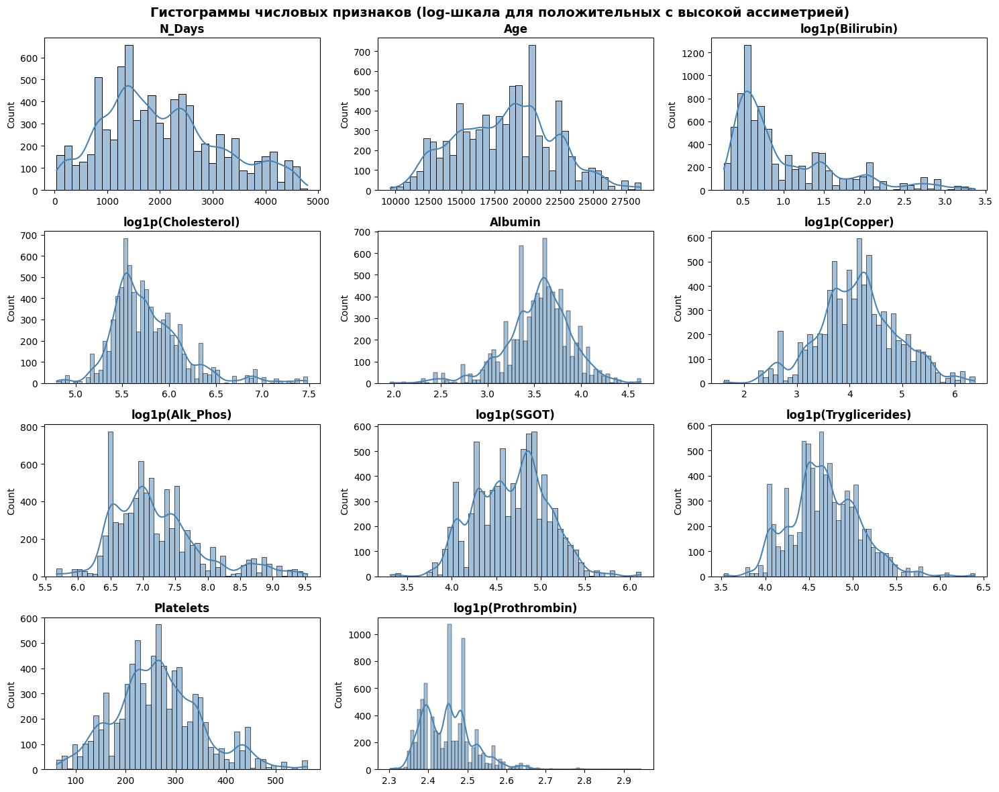

In [35]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for ax, c in zip(axes.flatten(), num_cols):
    data = df_clean[c].dropna()
    use_log = bool((data >= 0).all() and (data.skew() > 1.0))
    if use_log:
        sns.histplot(np.log1p(data), kde=True, ax=ax, color='steelblue')
        ax.set_title(f'log1p({c})', fontsize=12, fontweight='bold')
    else:
        sns.histplot(data, kde=True, ax=ax, color='steelblue')
        ax.set_title(c, fontsize=12, fontweight='bold')
    ax.set_xlabel('')
for ax in axes.flatten()[len(num_cols):]:
    ax.set_visible(False)
plt.suptitle('Гистограммы числовых признаков (log-шкала для положительных с высокой ассиметрией)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## **4.3 Boxplot + violinplot**

**Что смотреть:** «точки» за усами — формальные выбросы; «толстые» участки violin — модальные значения.

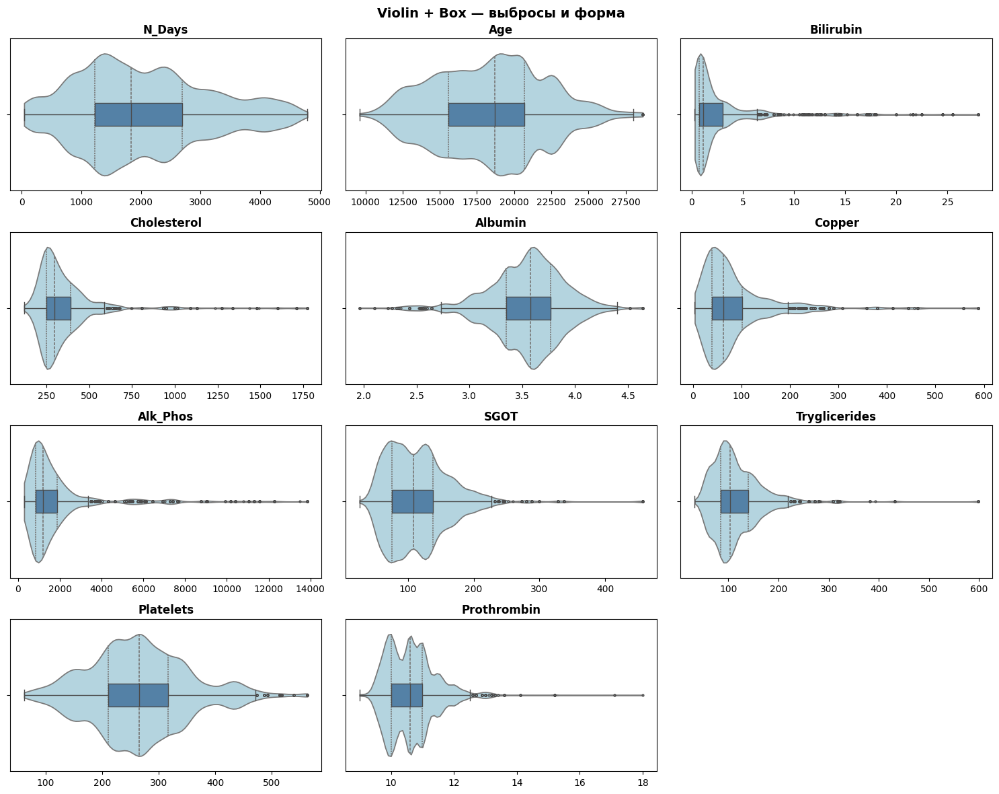

In [36]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for ax, c in zip(axes.flatten(), num_cols):
    sns.violinplot(x=df_clean[c], ax=ax, inner='quartile', color='lightblue', cut=0)
    sns.boxplot(x=df_clean[c], ax=ax, width=0.15, color='steelblue', fliersize=2)
    ax.set_title(c, fontsize=12, fontweight='bold')
    ax.set_xlabel('')
for ax in axes.flatten()[len(num_cols):]:
    ax.set_visible(False)
plt.suptitle('Violin + Box — выбросы и форма', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## **4.4 QQ-plot (нормальность)**

**Что смотреть:** отклонение от прямой на хвостах = ненормальность. Особенно полезно перед t-тестом или линейной регрессией.

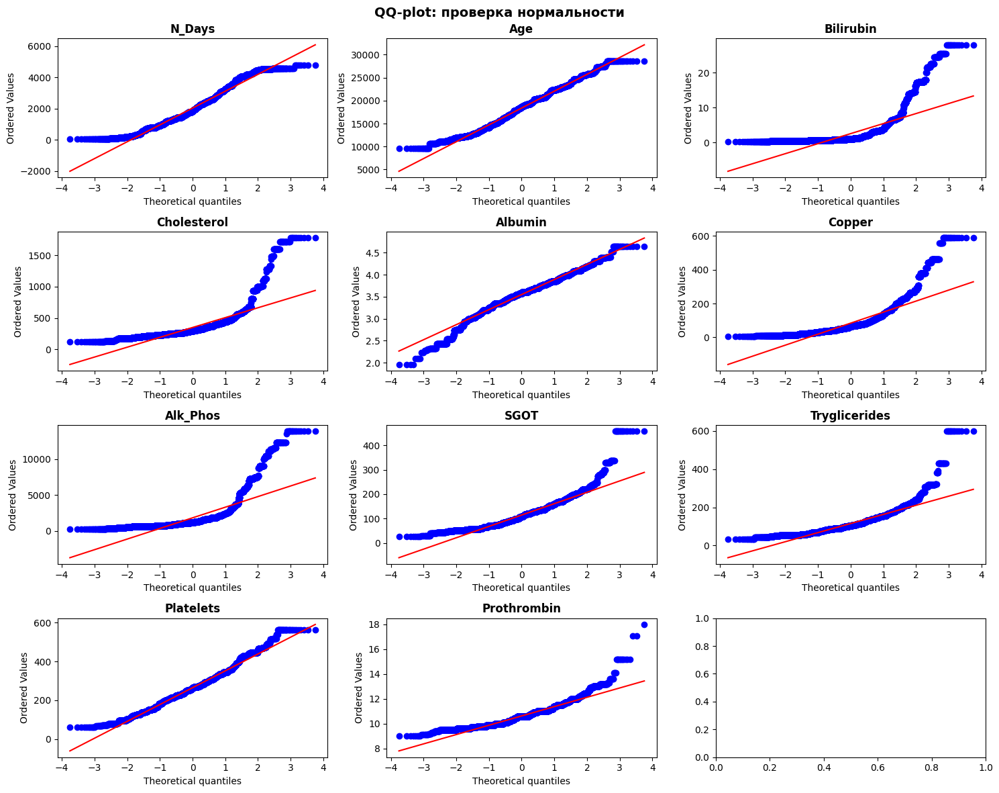

In [37]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for ax, c in zip(axes.flatten(), num_cols):
    stats.probplot(df_clean[c].dropna(), dist='norm', plot=ax)
    ax.set_title(c, fontsize=12, fontweight='bold')
plt.suptitle('QQ-plot: проверка нормальности', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## **4.5 Тесты нормальности (формальная проверка)**

**Что смотреть:** если `p < 0.05` — гипотеза нормальности отвергается. В этом датасете все признаки ненормальны → нужны лог-преобразования или непараметрические тесты.

In [38]:
results = []
for c in num_cols:
    s = df_clean[c].dropna()
    s_sample = s.sample(min(5000, len(s)), random_state=42)  # ограничение для Shapiro
    results.append({
        'feature': c,
        'Shapiro_p':  stats.shapiro(s_sample).pvalue,
        'DAgostino_p': stats.normaltest(s).pvalue,
        'skew': s.skew(),
        'kurt': s.kurt(),
        'is_normal_5%': stats.normaltest(s).pvalue > 0.05,
    })
pd.DataFrame(results).round(4)


,feature,Shapiro_p,DAgostino_p,skew,kurt,is_normal_5%
0,N_Days,0.0,0.0,0.4487,-0.4940,False
1,Age,0.0,0.0,0.0841,-0.4974,False
2,Bilirubin,0.0,0.0,3.3397,12.9088,False
3,Cholesterol,0.0,0.0,3.6797,18.1623,False
4,Albumin,0.0,0.0,-0.5611,1.3396,False
5,Copper,0.0,0.0,2.7017,10.2130,False
6,Alk_Phos,0.0,0.0,3.1956,11.5998,False
7,SGOT,0.0,0.0,1.5348,5.8168,False
8,Tryglicerides,0.0,0.0,2.6339,15.0481,False
9,Platelets,0.0,0.0,0.4200,0.3306,False


## **4.6 Категориальные признаки — частоты**

**Что смотреть:**
- Дисбаланс (`Status = C/D/CL`, `Edema = N/S/Y`) — важно для стратификации.
- Редкие категории — если у категории < 5 % наблюдений, её может стоить объединить.
- Доминирующий класс — если > 90 %, признак почти константа.

In [39]:
for c in cat_cols:
    vc = df_clean[c].value_counts().sort_index()
    pct = (vc / len(df_clean) * 100).round(1)
    print(f"\n=== {c} ===")
    print(pd.DataFrame({'count': vc, 'pct %': pct}))



=== Drug ===
                 count  pct %
Drug                         
D-penicillamine   3895   49.3
Placebo           4010   50.7

=== Sex ===
     count  pct %
Sex              
F     7336   92.8
M      569    7.2

=== Ascites ===
         count  pct %
Ascites              
N         7525   95.2
Y          380    4.8

=== Hepatomegaly ===
              count  pct %
Hepatomegaly              
N              3863   48.9
Y              4042   51.1

=== Spiders ===
         count  pct %
Spiders              
N         5966   75.5
Y         1939   24.5

=== Edema ===
       count  pct %
Edema              
N       7161   90.6
S        399    5.0
Y        345    4.4

=== Stage ===
       count  pct %
Stage              
1.0      397    5.0
2.0     1652   20.9
3.0     3153   39.9
4.0     2703   34.2

=== Status ===
        count  pct %
Status              
C        4965   62.8
CL        275    3.5
D        2665   33.7


## **4.7 Визуализация категориальных признаков (bar)**

**Что смотреть:** визуальный дисбаланс, редкие бары (< 5 %), «плоские» признаки (бинарные с сильным перекосом, например `Ascites ≈ 90 % N`).

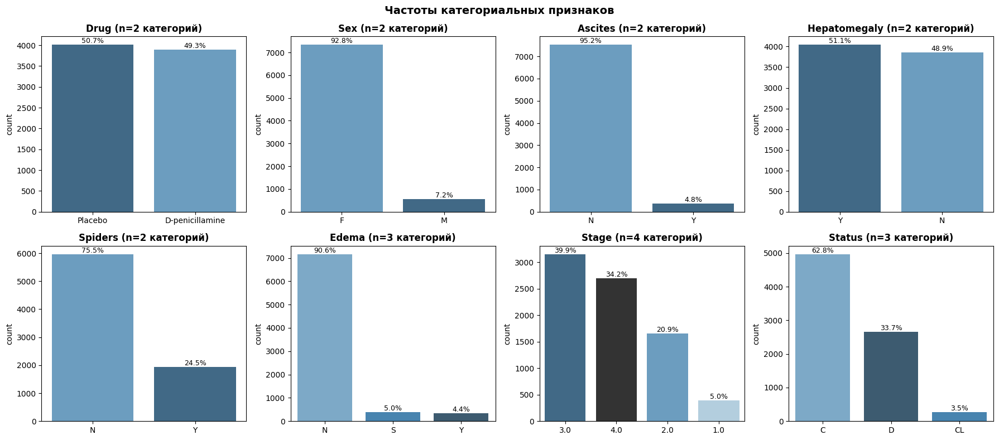

In [40]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.flatten(), cat_cols):
    order = df_clean[c].value_counts().index
    sns.countplot(data=df_clean, x=c, order=order, ax=ax,
                  palette='Blues_d', hue=c, legend=False)
    ax.set_title(f'{c} (n={df_clean[c].nunique()} категорий)',
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    for p in ax.patches:
        h = p.get_height()
        ax.annotate(f'{h/len(df_clean)*100:.1f}%',
                    (p.get_x()+p.get_width()/2, h),
                    ha='center', va='bottom', fontsize=9)
plt.suptitle('Частоты категориальных признаков', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## **4.8 Целевые признаки: Status и N_Days (survival-контекст)**

**Что смотреть:** доля `D` (смерть) vs `C` (цензурировано) — главный дисбаланс для задачи выживаемости. `N_Days` имеет длинный правый хвост (максимум ~4500 дней) — это нормально для survival-данных.

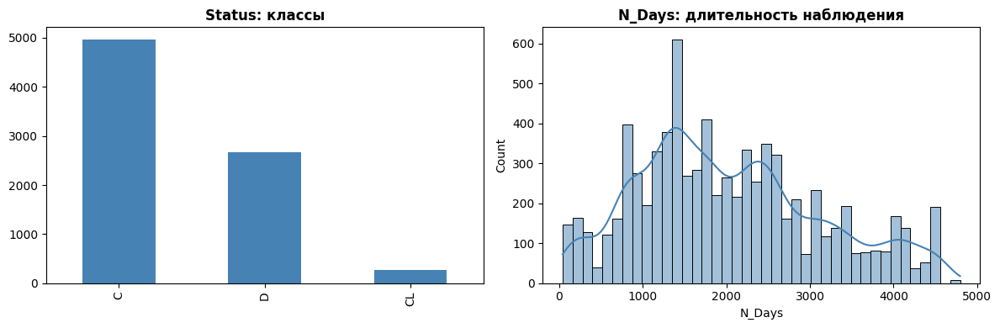

In [41]:
# 1. Распределение классов Status
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_clean['Status'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Status: классы', fontsize=12, fontweight='bold')
axes[0].set_xlabel('')

# 2. Длительность наблюдения
sns.histplot(df_clean['N_Days'], bins=40, kde=True, ax=axes[1], color='steelblue')
axes[1].set_title('N_Days: длительность наблюдения', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## **4.9 Kaplan-Meier кривые выживаемости**

Survival-специфичный график, который отображает выживаемость по стадии цирроза (`Stage`). Оценивает вероятность того, что событие (`D` — смерть) ещё не наступило к моменту `t` с учётом цензурирования.

**Что смотреть:** скорость падения кривых и их разделение по группам. Если кривые разных стадий хорошо разделяются — `Stage` значимый прогностический признак.

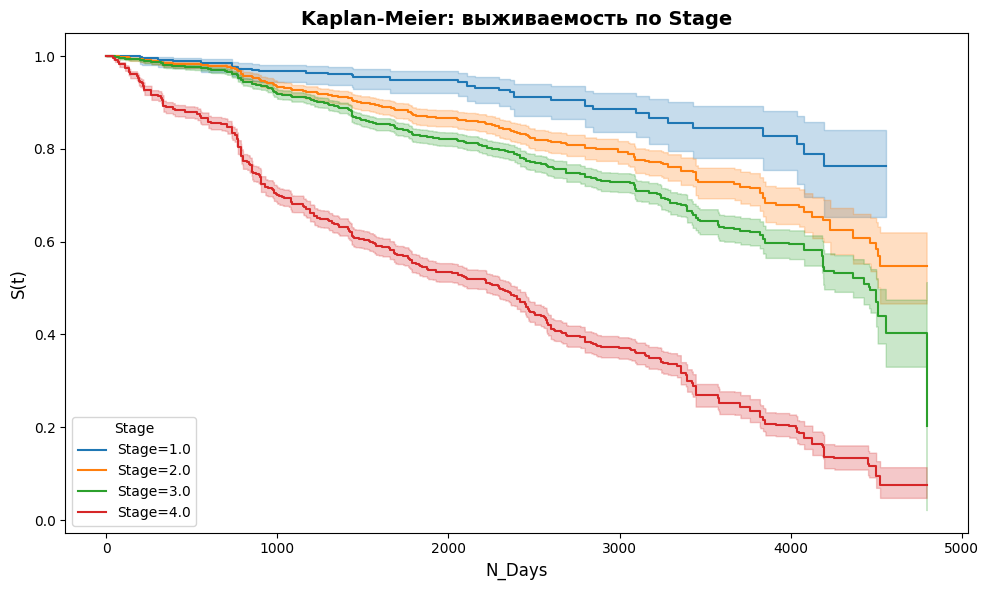

In [42]:
# lifelines — стандартная библиотека survival-анализа
from lifelines import KaplanMeierFitter

kmf = KaplanMeierFitter()

# 1. K-M по стадии цирроза
fig, ax = plt.subplots(figsize=(10, 6))
for stage, group in df_clean.groupby('Stage'):
    event = (group['Status'] == 'D').astype(int)
    kmf.fit(durations=group['N_Days'], event_observed=event,
          label=f'Stage={stage}')
    kmf.plot_survival_function(ax=ax)
ax.set_title('Kaplan-Meier: выживаемость по Stage',
             fontsize=14, fontweight='bold')
ax.set_xlabel('N_Days', fontsize=12)
ax.set_ylabel('S(t)', fontsize=12)
ax.legend(title='Stage')
plt.tight_layout()
plt.show()


## **4.10 Сводный одномерный отчёт**

**Что смотреть:** одна таблица — быстрый обзор всех признаков разом. Отлично подходит для отчёта перед моделированием.

In [43]:
def univariate_report(df, num_cols, cat_cols):
    rows = []
    for c in num_cols:
        s = df[c].dropna()
        rows.append({
            'type': 'numeric', 'feature': c, 'n': len(s),
            'min': s.min(), 'q25': s.quantile(.25), 'median': s.median(),
            'q75': s.quantile(.75), 'max': s.max(),
            'mean': s.mean(), 'std': s.std(),
            'skew': s.skew(), 'kurt': s.kurt(),
            'n_outliers_iqr': int(((s < s.quantile(.25) - 1.5*(s.quantile(.75) - s.quantile(.25))) |
                                   (s > s.quantile(.75) + 1.5*(s.quantile(.75) - s.quantile(.25)))).sum()),
        })
    for c in cat_cols:
        vc = df[c].value_counts()
        rows.append({
            'type': 'categorical', 'feature': c, 'n': int(df[c].notna().sum()),
            'n_categories': df[c].nunique(),
            'top': vc.index[0], 'top_pct': round(vc.iloc[0] / len(df) * 100, 1),
            'rarest_pct': round(vc.iloc[-1] / len(df) * 100, 1),
        })
    return pd.DataFrame(rows)

report = univariate_report(df_clean, num_cols, cat_cols)
display(report)


,type,feature,n,min,q25,median,q75,max,mean,std,skew,kurt,n_outliers_iqr,n_categories,top,top_pct,rarest_pct
0,numeric,N_Days,7905,41.00,1230.000000,1831.00,2689.000000,4795.000000,2030.173308,1094.233744,0.448660,-0.494017,0.0,NaN,NaN,NaN,NaN
1,numeric,Age,7905,9598.00,15574.000000,18713.00,20684.000000,28650.000000,18373.146490,3679.958739,0.084091,-0.497382,36.0,NaN,NaN,NaN,NaN
2,numeric,Bilirubin,7905,0.30,0.700000,1.10,3.000000,28.000000,2.594485,3.812960,3.339695,12.908825,789.0,NaN,NaN,NaN,NaN
3,numeric,Cholesterol,7905,120.00,248.000000,298.00,390.000000,1775.000000,350.561920,195.379349,3.679657,18.162327,502.0,NaN,NaN,NaN,NaN
4,numeric,Albumin,7905,1.96,3.350000,3.58,3.770000,4.640000,3.548322,0.346171,-0.561149,1.339621,178.0,NaN,NaN,NaN,NaN
5,numeric,Copper,7905,4.00,39.000000,63.00,102.000000,588.000000,83.902847,75.899269,2.701736,10.212990,655.0,NaN,NaN,NaN,NaN
6,numeric,Alk_Phos,7905,289.00,834.000000,1181.00,1857.000000,13862.400391,1816.745239,1903.750610,3.195558,11.599751,792.0,NaN,NaN,NaN,NaN
7,numeric,SGOT,7905,26.35,75.949997,108.50,137.949997,457.250000,114.604599,48.790947,1.534806,5.816788,146.0,NaN,NaN,NaN,NaN
8,numeric,Tryglicerides,7905,33.00,84.000000,104.00,139.000000,598.000000,115.340164,52.530403,2.633921,15.048119,267.0,NaN,NaN,NaN,NaN
9,numeric,Platelets,7905,62.00,211.000000,265.00,316.000000,563.000000,265.228973,87.465576,0.420048,0.330578,114.0,NaN,NaN,NaN,NaN


Одномерный анализ выявил сильные правосторонние скошенности лабораторных показателей (`Bilirubin`, `Copper`, `Alk_Phos`, `SGOT`), что подтверждает необходимость `log1p`-преобразования. Тесты нормальности отвергают гипотезу нормальности для всех признаков. Kaplan-Meier кривые по стадиям демонстрируют статистически значимое разделение.

# **Часть 5. Многомерный анализ**

## **5.1 Pairplot**

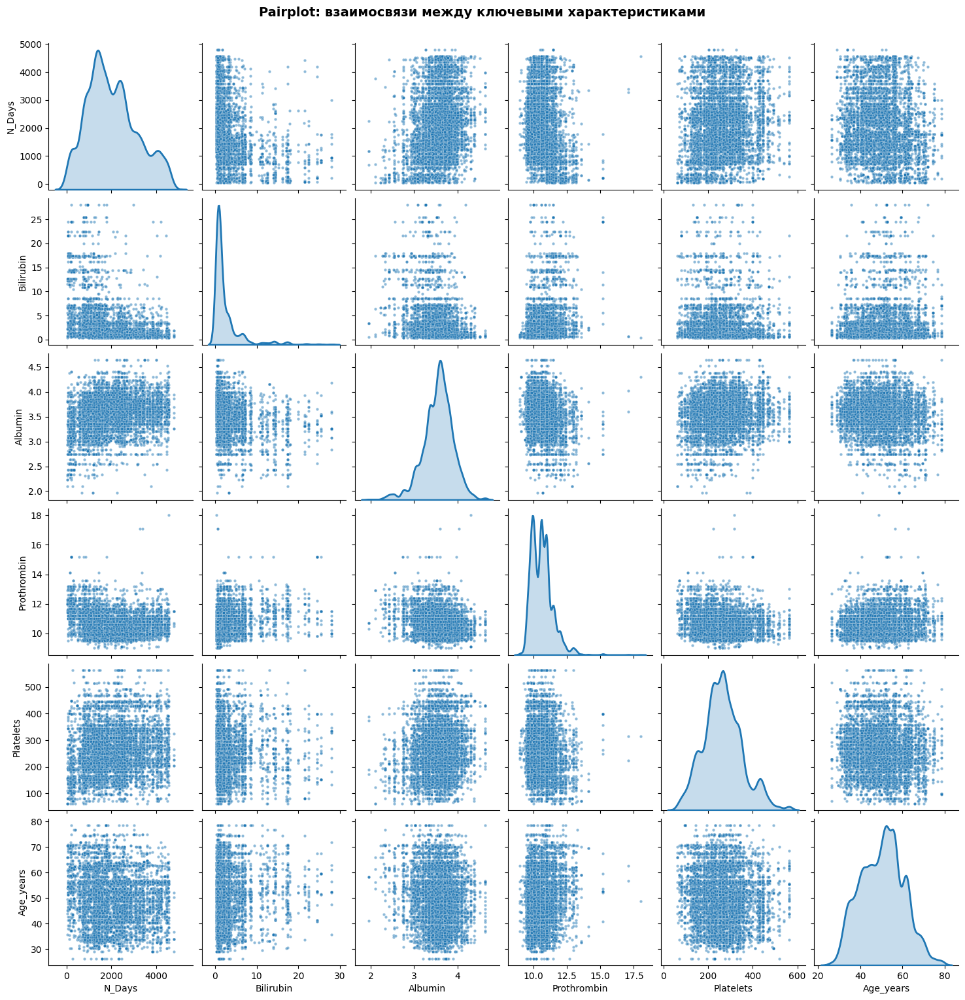

In [44]:
# На случай дубликатов id — работаем на уникальной выборке
df_unique = df_clean.drop_duplicates(subset='id')

pair_cols = ['N_Days', 'Bilirubin', 'Albumin', 'Prothrombin',
             'Platelets', 'Age_years']

sns.pairplot(df_unique[pair_cols],
             diag_kind='kde',
             plot_kws={'alpha': 0.5, 's': 10},
             diag_kws={'linewidth': 2})
plt.suptitle('Pairplot: взаимосвязи между ключевыми характеристиками',
             fontsize=14, fontweight='bold', y=1.02)
plt.show()


## **5.2 Корреляционный анализ с φk (phik)**

In [45]:
# Импорт библиотеки phik
import phik
from phik import resources, report


### Почему матрица построена по итоговому набору признаков

Матрицу связей строим не по всем 30 столбцам, а по тем 15 признакам, которые отобраны для модели в блоках 2.5, 3.10, 3.12 и 3.13. Причина простая: если положить в матрицу и показатель, и его копию, половина ячеек покажет почти единичную связь между ними. Такая картинка загораживает настоящие взаимосвязи данных — она говорит не о пациентах, а о том, что мы сами создали дубликаты.

В матрицу дополнительно включён `N_Days`, хотя в модель он не идёт. Он нужен здесь как наглядное напоминание о выводах блока 3.10: связь периода с исходом одна из самых сильных, и именно поэтому так важно не принять следствие за причину.

**Что такое φk.** Обычная корреляция Пирсона считает только линейную связь между числами, а коэффициент Крамера — только между категориями. φk (фи-ке) работает в обоих случаях и умеет улавливать нелинейные связи, поэтому одна матрица описывает и лабораторные показатели, и бинарные признаки, и цель.

| Исключено из матрицы | Почему |
|---|---|
| `Bilirubin`, `Copper`, `Alk_Phos`, `SGOT`, `Cholesterol`, `Tryglicerides` | их лог-варианты взяты в модель как основные |
| `Age`, `Edema`, `is_severe` | их заменяют `Age_years`, `Edema_num`, `Stage` |
| `Ascites` | дублирует отёки, исключён в блоке 3.12 |
| `is_dead` | утечка цели |
| `Drug`, `id` | неинформативны (блок 3.13) |

### Матрица корреляций φk

В матрице φk: 17 столбцов (15 признаков модели + период + цель)
Исключено как дубликаты или неинформативные (16): ['Age', 'Alk_Phos', 'Ascites', 'Ascites_Y', 'Bilirubin', 'Cholesterol', 'Copper', 'Drug', 'Edema', 'Hepatomegaly', 'SGOT', 'Sex', 'Spiders', 'Tryglicerides', 'is_dead', 'is_severe']


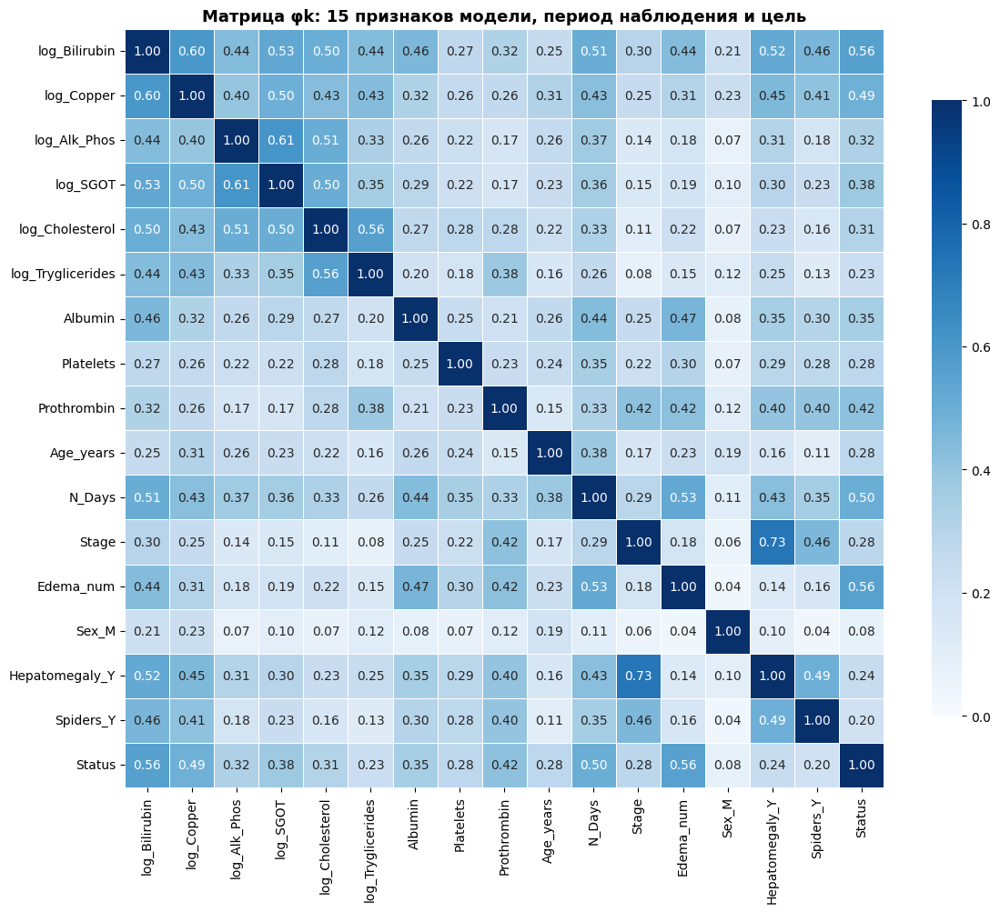

Связь каждого признака с целью (по убыванию):


,φk со Status
log_Bilirubin,0.563
Edema_num,0.558
N_Days,0.502
log_Copper,0.489
Prothrombin,0.417
log_SGOT,0.378
Albumin,0.349
log_Alk_Phos,0.323
log_Cholesterol,0.312
Stage,0.284


In [46]:
# df_unique уже создан в блоке 5.1 (это df_clean без дубликатов по id)

# Итоговый набор признаков модели + период для наглядности + цель
interval_cols = [c for c in FINAL_FEATURES if df_unique[c].nunique() > 6] + ['N_Days']
binary_cols = [c for c in FINAL_FEATURES if c not in interval_cols]
categorical_cols = binary_cols + ['Status']

subset_cols = interval_cols + categorical_cols
dropped = [c for c in df_unique.columns if c != 'id' and c not in subset_cols]
print(f'В матрице φk: {len(subset_cols)} столбцов (15 признаков модели + период + цель)')
print(f'Исключено как дубликаты или неинформативные ({len(dropped)}): {sorted(dropped)}')

# Считаем phik-матрицу в один поток (njobs=1), чтобы обойти баг сериализации в pandas 3+
phik_matrix = df_unique[subset_cols].phik_matrix(
    interval_cols=interval_cols,
    njobs=1
)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(phik_matrix, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
            square=True, linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Матрица φk: 15 признаков модели, период наблюдения и цель',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Сортировка связей с целью — самый полезный срез матрицы
with_target = phik_matrix['Status'].drop('Status').sort_values(ascending=False)
print('Связь каждого признака с целью (по убыванию):')
display(with_target.round(3).to_frame('φk со Status'))

### Как читать матрицу

| Значение φk | Что это значит |
|---|---|
| 0.00 – 0.15 | связи практически нет |
| 0.15 – 0.30 | слабая связь |
| 0.30 – 0.50 | умеренная связь |
| выше 0.50 | сильная связь |

**Что видно в матрице и что из этого следует.**

1. **Сильнее всего с исходом связаны логарифм билирубина, медь, протромбин и AST** — показатели работы и повреждения печени. Это клинически ожидаемо: чем тяжелее поражение органа, тем выше билирубин и медь и тем хуже свёртываемость крови. Модель опирается на правильные данные.

2. **Период наблюдения стоит в этом ряду очень высоко** — и это ровно та ловушка, о которой говорилось в блоке 3.10. Сильная связь здесь не означает, что период полезен как прогноз: он возникает после исхода, а не до него.

3. **Между собой признаки связаны умеренно, сильнее всего — логарифмы билирубина и меди, а также стадия с увеличением печени.** Это разные измерения одного и того же процесса — тяжести болезни. Столь тесных пар, чтобы пришлось жертвовать признаком, в итоговом наборе нет: проверка в блоке 3.12 нашла одну пару выше порога 0.6, и она уже разрешена.

4. **Бинарные признаки (мужской пол, увеличенная печень, «паучки») связаны с исходом слабее лабораторных показателей, но связь не нулевая** — они остаются в модели.

Сравните с исходной версией этого раздела: до удаления дубликатов матрица содержала ячейки с единичной связью между показателем и его логарифмом, и они затеняли всё остальное. На итоговом наборе таких ячеек нет — матрица показывает свойства данных, а не последствия нашей инженерии.

# **Часть 6. Сегментированный анализ**

## **6.1 Стадии и медианное время наблюдения**

**Что смотреть:** Stage 1 должен давать наибольшую медиану `N_Days`, Stage 4 — наименьшую. Если порядок нарушен — либо шум из-за малых подгрупп, либо данные требуют пересмотра.

In [47]:
# Топ-5 стадий по медианной выживаемости (N_Days)
top_stages_by_days = (
    df_clean[df_clean['N_Days'] != 0]
      .groupby('Stage', observed=True)['N_Days']
      .median()
      .sort_values(ascending=False)
      .head(5)
)

print('Топ-5 стадий по медианной выживаемости (N_Days):')
print(top_stages_by_days.round(1))

# Ключевые лабораторные признаки для сравнения
features_for_comparison = ['Bilirubin', 'Albumin', 'Prothrombin',
                           'Platelets', 'Copper', 'SGOT']

# Медианы по группам
selected_stages = top_stages_by_days.index.tolist()
stage_stats = (df_clean[df_clean['Stage'].isin(selected_stages)]
               .groupby('Stage', observed=True)[features_for_comparison]
               .median())

print('\nМедианы ключевых признаков по стадиям:')
display(stage_stats.round(2))


Топ-5 стадий по медианной выживаемости (N_Days):
Stage
1.0    2255.0
2.0    2221.0
3.0    1951.0
4.0    1455.0
Name: N_Days, dtype: float64

Медианы ключевых признаков по стадиям:


,Bilirubin,Albumin,Prothrombin,Platelets,Copper,SGOT
Stage,,,,,,
1.0,0.8,3.64,10.5,271.0,52.0,93.000000
2.0,0.9,3.63,10.4,271.0,52.0,97.650002
3.0,0.9,3.61,10.4,269.0,57.0,102.300003
4.0,2.0,3.48,11.0,233.0,76.0,120.000000


## **6.2 Radar Chart: профили стадий**

**Radar Chart** — удобный инструмент для сравнения многомерных профилей.
Каждая стадия представлена как «паутина», где:
- Оси — клинические признаки.
- Расстояние от центра — медианный percentile rank признака.
- Форма «паутины» — уникальный профиль группы пациентов.

**Зачем percentile rank:** признаки измеряются в разных единицах (мг/дл, Ед/л, ×1000/мкл), поэтому приводим каждый к единой шкале [0, 1].

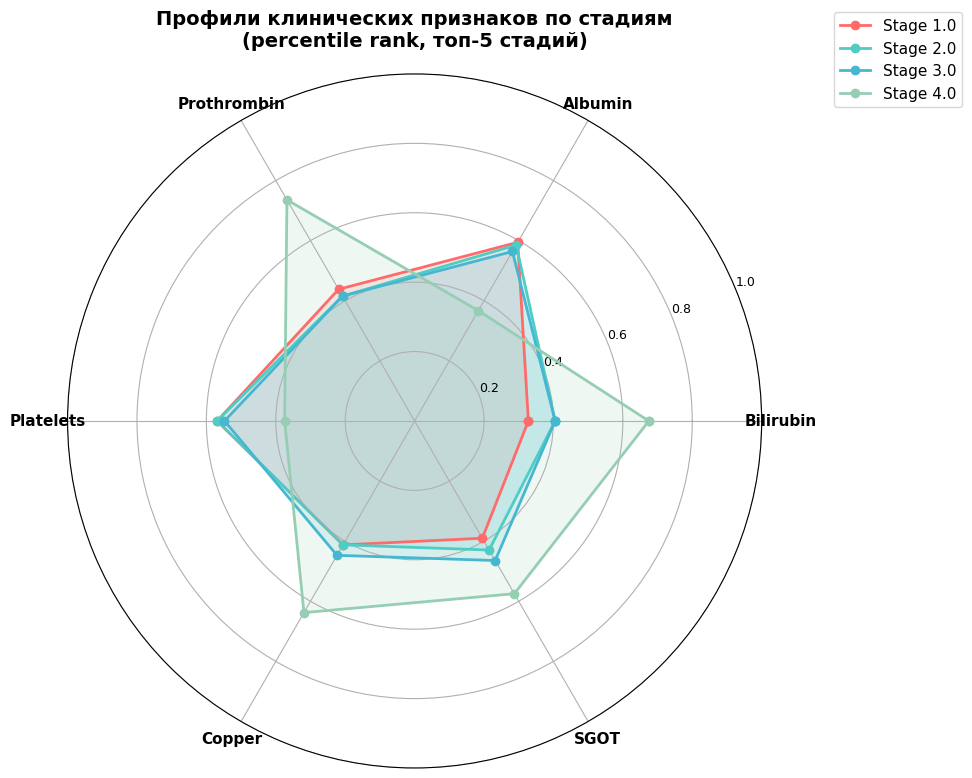

In [48]:
radar_features = ['Bilirubin', 'Albumin', 'Prothrombin', 'Platelets', 'Copper', 'SGOT']

# 1. Нормализация: percentile rank по всей выборке -> [0, 1]
df_radar = df_clean.copy()
for c in features_for_comparison:
    df_radar[c] = df_radar[c].rank(pct=True)

# 2. Медианы по группам в нормализованной шкале
group_stats = (df_radar[df_radar['Stage'].isin(selected_stages)]
    .groupby('Stage', observed=True)[features_for_comparison]
    .median())

# 3. RADAR CHART
categories = features_for_comparison
N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]  # замыкаем круг

colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7']

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

for idx, group in enumerate(selected_stages):
    values = group_stats.loc[group].values.flatten().tolist()
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2,
            label=f'Stage {group}', color=colors[idx])
    ax.fill(angles, values, alpha=0.15, color=colors[idx])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=9)

ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=11)
ax.set_title('Профили клинических признаков по стадиям\n'
    '(percentile rank, топ-5 стадий)',
    fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()


## **6.3 Radar Chart: сравнение двух групп (универсальная функция)**

Сравнение бинарных сегментов (умершие vs выжившие, тяжёлые vs лёгкие) обобщаем в переиспользуемую функцию `radar_binary_compare`: принимает бинарный признак (`is_dead`, `is_severe`) и набор признаков — строит radar-сравнение по медианам percentile rank.

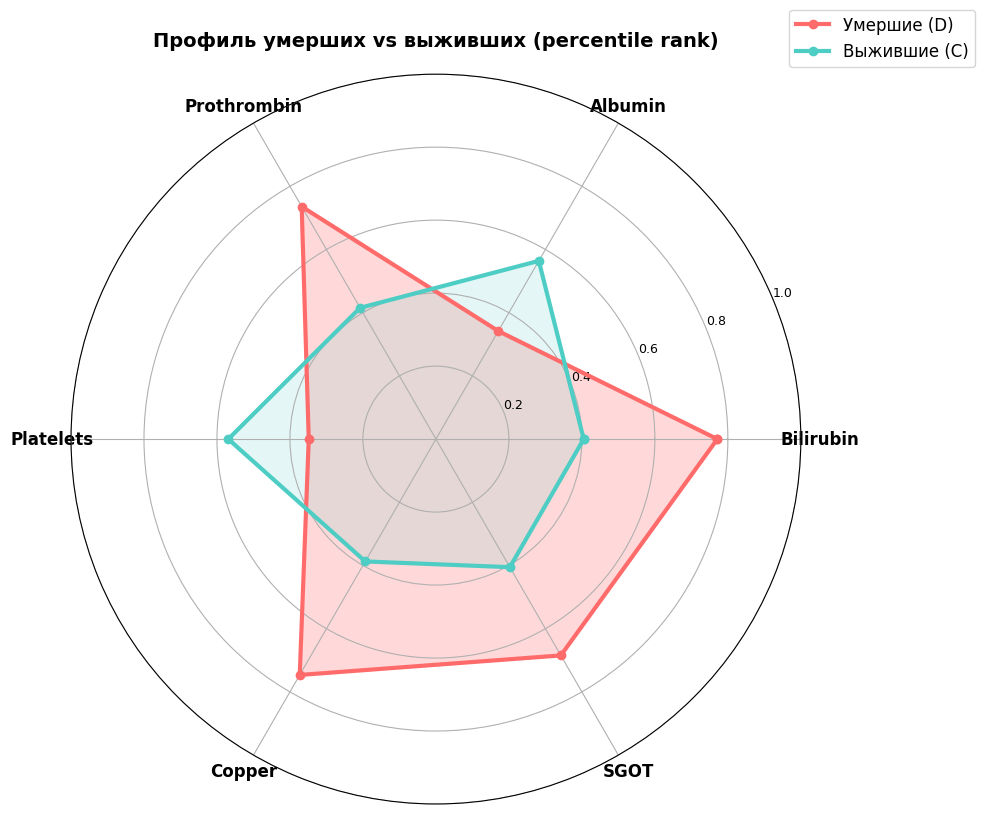

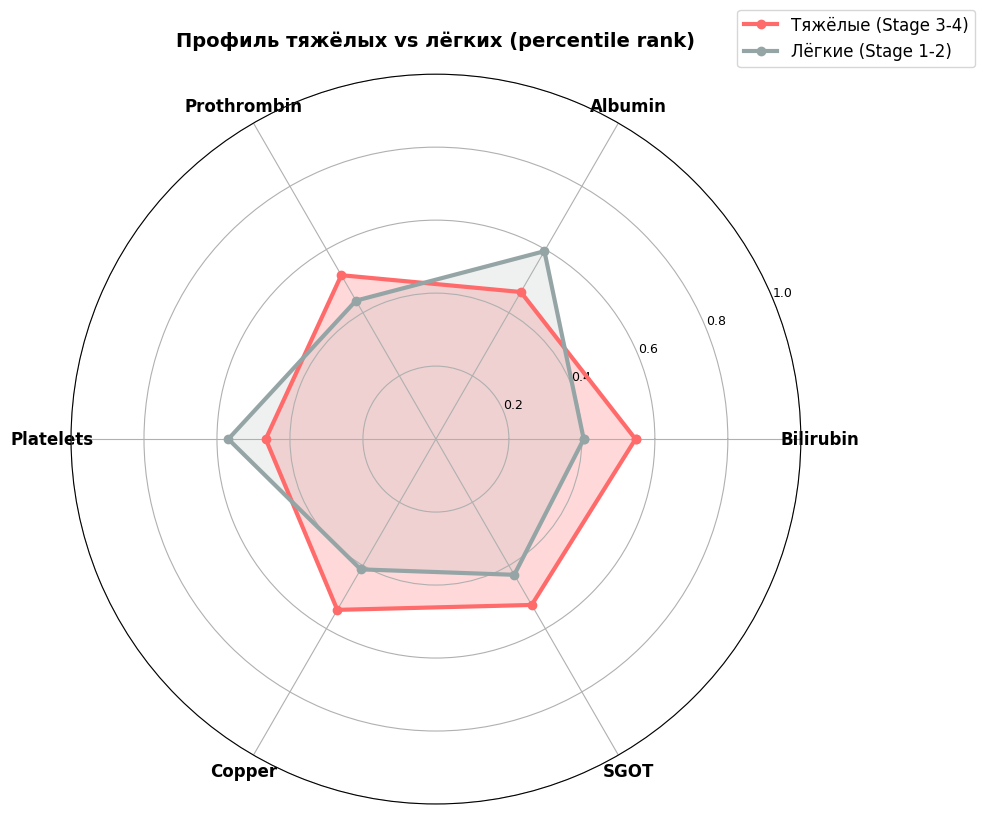

In [49]:
def radar_binary_compare(df, bin_col, features, label_1, label_0,
                         color_1='#FF6B6B', color_0='#95A5A6',
                         title=None):
    """Radar-сравнение двух групп по percentile rank признаков.

    bin_col — имя бинарной колонки 0/1 в df.
    features — список числовых признаков для сравнения.
    """
    data = df.copy()
    for c in features:
        data[c] = data[c].rank(pct=True)

    stats_ = data.groupby(bin_col, observed=True)[features].median()
    categories = features
    N = len(categories)
    angles = [n / float(N) * 2 * pi for n in range(N)] + [0]

    v1 = stats_.loc[1].values.tolist(); v1 += [v1[0]]
    v0 = stats_.loc[0].values.tolist(); v0 += [v0[0]]

    fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))
    ax.plot(angles, v1, 'o-', linewidth=3, label=label_1, color=color_1)
    ax.fill(angles, v1, alpha=0.25, color=color_1)
    ax.plot(angles, v0, 'o-', linewidth=3, label=label_0, color=color_0)
    ax.fill(angles, v0, alpha=0.15, color=color_0)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize=12, fontweight='bold')
    ax.set_ylim(0, 1)
    ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=9)

    ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1), fontsize=12)
    ax.set_title(title or f'Radar: {label_1} vs {label_0}',
        fontsize=14, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.show()


# Пример 1: умершие vs выжившие (флаг is_dead создан в блоке 2.5)
radar_binary_compare(
    df_clean, 'is_dead', radar_features,
    label_1='Умершие (D)', label_0='Выжившие (C)',
    color_1='#FF6B6B', color_0='#4ECDC4',
    title='Профиль умерших vs выживших (percentile rank)',
)

# Пример 2: тяжёлые vs лёгкие (флаг is_severe создан в блоке 2.5)
radar_binary_compare(
    df_clean, 'is_severe', radar_features,
    label_1='Тяжёлые (Stage 3-4)', label_0='Лёгкие (Stage 1-2)',
    color_1='#FF6B6B', color_0='#95A5A6',
    title='Профиль тяжёлых vs лёгких (percentile rank)',
)


Radar-диаграммы на percentile rank наглядно показывают, какие клинические признаки наиболее сильно различают группы: умершие пациенты имеют более высокие `Bilirubin`, `Copper` и `Prothrombin`, но более низкие `Albumin` и `Platelets`. Тяжёлые стадии (3–4) также демонстрируют выраженные отклонения по всем ключевым показателям.

# **Часть 7. Автоматизация EDA с ydata-profiling**

In [50]:
# Импорт
from ydata_profiling import ProfileReport


/tmp/ipykernel_366775/1890097276.py:2: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


## **7.2 Генерация отчёта**

In [51]:
# Генерация отчёта (может занять 1-2 минуты)
profile = ProfileReport(
    df_clean,
    title='Cirrhosis Outcomes EDA Report',
    explorative=True,
    correlations={
        'auto': {'calculate': False},
        'phi_k': {'calculate': True},
    },
)
profile


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/34 [00:00<?, ?it/s]

100%|██████████| 34/34 [00:00<00:00, 5752.11it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [52]:
# Сохранение отчёта в HTML-файл
profile.to_file('cirrhosis_eda_report.html')


Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

ydata-profiling автоматически проверяет пропуски, дубликаты, распределения, корреляции и предупреждает о проблемных колонках. Это надёжный чек-лист, который помогает не упустить очевидные проблемы качества данных.


# **Итоги анализа**

## **1. Что можно сказать о пациентах и данных**

- **Исходы распределены неравномерно.** Живы на конец наблюдения 4 965 пациентов (62.8 %), умерли 2 665 (33.7 %), перенесли трансплантацию 275 (3.5 %). Последний класс мал — на нём модель будет ошибаться чаще всего, и это надо учитывать при оценке качества.

- **Результаты анализов распределены крайне неровно.** У большинства пациентов билирубин и медь в пределах нормы, но у небольшой группы отклонения в десятки раз. Такие показатели перед моделированием приводят к логарифмической шкале — иначе единичные тяжёлые пациенты вытягивают всю модель за собой.

- **Стадия поражения печени согласуется с анализами**: чем выше стадия, тем выше билирубин, медь и протромбиновое время и тем ниже альбумин и тромбоциты. Данные внутренне непротиворечивы — это важный признак их качества.

- **Стадия значимо влияет на выживаемость.** Кривые выживаемости по стадиям расходятся статистически значимо, значит стадия — сильный прогнозический признак.

- **Большинство «выбросов» — это тяжёлые пациенты, а не ошибки ввода.** Формальное правило отсечения выбросов удалило бы самых больных, то есть наиболее интересных для задачи. Мы их сохранили.

- **Препарат не связан с исходом.** Распределение исходов в группах препарата и плацебо статистически неразличимо (вероятность 0.053). Это подтверждает корректность рандомизации исследования, но делает признак бесполезным для прогноза.

## **2. Какие признаки отобраны для модели и почему**

Из 30 столбцов очищенного датасета в модель идут **15**. Отбор опиралс�� на три независимых основания, и каждое отсеяло своё:

| Основание | Сколько и какие столбцы отсечены |
|---|---|
| **Дублирование** — один и тот же факт записан дважды | 10 столбцов: шесть анализов, у которых в модель идёт логарифм, а не исходное значение; `Age` (заменён `Age_years`); `Edema` (заменён `Edema_num`); `is_severe` (заменён `Stage`); `Ascites` (повторяет отёки, корреляция 0.635) |
| **Нет связи с исходом** | `Drug` (связь 0.013), `id` (технический номер) |
| **Подглядывание в ответ** | `is_dead` — это буквально половина ответа; `N_Days` — период наблюдения, известен только после исхода |

**Правило «одна информация — один столбец» — главное в этом отборе.** Инженерные признаки (логарифмы, возраст в годах, флаги) сделаны для удобства человека, но модель читает числа и не различает «удобную» и «исходную» форму одного и того же факта. Положить в модель и билирубин, и его логарифм — всё равно что спросить у пациента одно и то же дважды и сделать вид, что получил два независимых ответа. Вес при признаке перестаёт отвечать на вопрос «как этот показатель влияет на исход», а выводы из такой модели становятся ненадёжными.

**Почему из пары «асцит — отёки» убран асцит.** Проверка на пяти частях данных (кросс-валидация) показала: без асцита качество не меняется вообще (доля верных ответов 0.7997 против 0.8000, разница меньше разброса между частями проверки), а без отёков модель заметно хуже. Более простой набор при равном качестве предпочтительнее.

## **3. Решение по периоду наблюдения**

Период наблюдения — сколько дней пациент провёл под наблюдением до развязки — это самый обманчивый столбец датасета.

Он очень сильно связан с исходом (φk = 0.50, один из самых высоких показателей). Но связь работает **в обратную сторону**: не период влияет на исход, а исход определяет период. Пациент, умерший на 400-й день, наблюдаться дольше не мог физически.

Проверки подтверждают это:

- Если приравнять период у всех пациентов к максимальному (4 795 дней), исходы не изменятся ни у одного — период на них не влияет.
- Среди пациентов с одинаковым периодом около 70 % живы и около 25 % умерли: один и тот же период даёт все исходы.
- 90 % умерших наблюдались от 140 до 3 820 дней — интервалы классов перекрываются, по периоду их не разделить.

**Принято решение: период в модель исхода не включать.** Контрольный опыт на стадии 3 покажет, что и качество от его удаления почти не страдает (разница на уровне статистического шума), то есть ничего ценного мы не теряем.

Рассматривался и вариант «двухэтапного» использования: сначала предсказать исход, а зная его — предсказать период. Проверка показала, что период объясняется клиническими данными лишь на 22 %, а знание исхода добавляет ещё 0.8 процентного пункта. Выигрыш не оправдывает удвоения сложности, и от этого варианта отказались.

**Почему это важно зафиксировать явно.** Модель, использующая период, показывает красивые цифры на этих данных, но неприменима к пациенту, который пришёл на приём сегодня: его период ещё не наступил.

## **4. Рекомендации для стадий моделирования**

| Вопрос | Рекомендация | Обоснование |
|---|---|---|
| Данные | Читать `train_model.parquet` | набор из 15 признаков уже собран и обоснован |
| Метод | Не использовать оценку по числу (линейную регрессию); использовать классификацию | исход — категория, а не число; проверка предпосылок на стадии 2 |
| Разбиение данных | Делить с сохранением долей исходов (стратифицированно) | редкий класс может не попасть в проверку |
| Оценка качества | Не полагаться на долю верных ответов | при дисбалансе она скрывает провал на редком классе |
| Метрика | Средняя F-мера по классам и логарифмическая потеря | учитывают качество на малом классе |
| Редкий класс | Взвешивание ошибок по классам | без него трансплантация не находится вовсе |

## **5. Ограничения анализа**

- **Данные синтетические** — сгенерированы моделью по мотивам реального датасета UCI. Редкие классы и хвосты распределений могут отличаться от реальной популяции пациентов.
- **Период наблюдения и исход описывают только конец наблюдения.** Причинный эффект препарата в рамках этой работы не оценивался: нас интересует прогноз, а не лечение.
- **Матрицы связей и радар-диаграммы — визуальные инструменты.** Статистическая значимость связей проверялась тестами в блоках 3.12 и 3.13, но причинно-следственные выводы из них не делаются.